# Week 4 assignment: The Forecast Showdown
**Ioannis Tzalas | MSc Banking and Finance | October 2026**

## Pre-registered holdout — declared before any model
**2024-10-01.** A fixed quarter boundary leaves almost two years for testing and a substantial prior training sample. I will not change it after seeing forecast scores. The analysis is retrospective: the historical period was available in earlier coursework, so this is a predeclared modelling split, not a prospective experiment.

I retain **SPY, EUR/USD, BTC, GLD and ETH**, with GLD and ETH as my chosen assets. Each observed, positive price series from the exact Week 2 embedded union panel stays on its own calendar; I do not intersect dates or interpolate missing prices. Crypto weekends remain. Models are univariate, with annualization 252 for SPY, EUR/USD and GLD, 365 for BTC and ETH. Main outputs use frozen data through the Week 2 endpoint, not newly downloaded prices.

The supplied 2026 assignment and unified notebook define the protocol. The additional no-maths PDF is a supplementary older handout (dated 2025), not a replacement for the 2026 holdout, benchmark or scoring rules. All numerical interpretations below are tied to the displayed sample. Each null is stated before its p-value; failure to reject is not proof of truth.

In [1]:
import io, base64, gzip, json, hashlib, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels, statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, coint
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning, ConvergenceWarning, ValueWarning
import arch
from arch import arch_model
from IPython.display import display
for w in [InterpolationWarning,ValueWarning,FutureWarning]: warnings.filterwarnings('ignore',category=w)
pd.set_option('display.max_columns',30)
plt.rcParams.update({'figure.figsize':(12,5),'axes.spines.top':False,'axes.spines.right':False})
OUTPUT=Path.cwd()
for folder in ['results','charts']:(OUTPUT/folder).mkdir(exist_ok=True)
TEST_START=pd.Timestamp('2024-10-01'); REFIT=63
ASSETS=['SPY','EUR/USD','BTC','GLD','ETH']; CHOSEN=['GLD','ETH']
PPY={a:365 if a in ['BTC','ETH'] else 252 for a in ASSETS}
interpretations={}
EMBEDDED='...'
raw=gzip.decompress(base64.b64decode(EMBEDDED))
union=pd.read_csv(io.BytesIO(raw),index_col=0,parse_dates=True)
prices={a:union[a].dropna().astype(float) for a in ASSETS}
for a,p in prices.items():
 assert p.index.is_unique and p.index.is_monotonic_increasing and (p>0).all()
ret={a:np.log(p).diff().dropna().rename(a) for a,p in prices.items()}
train={a:r[r.index<TEST_START] for a,r in ret.items()};test={a:r[r.index>=TEST_START] for a,r in ret.items()}
COURSE_FUNCTIONS={'load_price_file': 'def load_price_file(stem: str) -> pd.Series | None:\n    \'\'\'Week-2 loader: Close series from data/{stem}.csv (or .xlsx); None if absent or broken.\'\'\'\n    for ext in (".csv", ".xlsx"):\n        f = DATA_DIR / f"{stem}{ext}"\n        if not f.exists():\n            continue\n        df = pd.read_csv(f) if ext == ".csv" else pd.read_excel(f)\n        df.columns = [str(c).strip() for c in df.columns]\n        date_col = next((c for c in df.columns if c.lower().startswith("date")), df.columns[0])\n        px_col   = next((c for c in df.columns if c.lower() in ("close", "adj close", "adj_close")), None)\n        if px_col is None:\n            return None\n        s = pd.Series(pd.to_numeric(df[px_col], errors="coerce").values, index=pd.to_datetime(df[date_col], errors="coerce"))\n        s = s[s.index.notna()].sort_index().dropna()\n        return s if len(s) > 500 else None\n    return None', 'arma_garch_path': "def arma_garch_path(rng, n, phi, theta, mu, sig, alpha, beta, df):\n    '''ARMA(1,1) mean + GARCH(1,1) variance + Student-t shocks: every Week-1 stylized fact in twelve lines.'''\n    omega = sig**2 * (1 - alpha - beta)                       # so that the unconditional variance is sig²\n    z = rng.standard_t(df, n) / np.sqrt(df / (df - 2))       # unit-variance t shocks (fat tails)\n    r, e, s2 = np.zeros(n), np.zeros(n), np.full(n, sig**2)\n    for t in range(n):\n        if t:\n            s2[t] = omega + alpha * e[t-1]**2 + beta * s2[t-1]   # yesterday's shock and yesterday's variance\n        e[t] = np.sqrt(s2[t]) * z[t]\n        r[t] = mu + e[t] + (phi * (r[t-1] - mu) + theta * e[t-1] if t else 0.0)\n    return r", 'generate_synthetic_market': 'def generate_synthetic_market():\n    prices = {}\n    for stem, (cal, s0, phi, theta, mu, sig, a, b, df, stream) in TRUE.items():\n        rng = np.random.default_rng([42, stream])            # one independent, reproducible stream per asset\n        idx = pd.date_range(START, END_SYN, freq=cal)\n        r   = arma_garch_path(rng, len(idx), phi, theta, mu, sig, a, b, df)\n        prices[stem] = pd.Series(s0 * np.exp(np.cumsum(r)), index=idx)\n    return prices', 'stationarity_exam': 'def stationarity_exam(s: pd.Series) -> dict:\n    \'\'\'ADF (H0: unit root) and KPSS (H0: stationary) with a constant. Verdict only when the two agree.\'\'\'\n    s = s.dropna()\n    adf_stat, adf_p, *_ = adfuller(s, regression="c", autolag="AIC")\n    kp_stat, kp_p, *_   = kpss(s, regression="c", nlags="auto")\n    adf_ok, kp_ok = adf_p < 0.05, kp_p >= 0.05\n    verdict = ("stationary ✅" if adf_ok and kp_ok else\n               "UNIT ROOT ⚠️" if (not adf_ok and not kp_ok) else "inconclusive ❓")\n    return {"ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kp_stat, "KPSS p": kp_p, "verdict": verdict}', 'select_arma': 'def select_arma(r: pd.Series, max_p=2, max_q=2):\n    \'\'\'Fit every ARMA(p,q) on the grid; return the BIC table (relative to white noise) and the winner.\'\'\'\n    fits = {}\n    for p in range(max_p + 1):\n        for q in range(max_q + 1):\n            try:\n                fits[(p, q)] = ARIMA(r.values, order=(p, 0, q), trend="c").fit()\n            except Exception:\n                pass\n    bic   = pd.Series({k: m.bic for k, m in fits.items()})\n    table = (bic - bic[(0, 0)]).unstack()                        # ΔBIC vs the constant-only model; negative = better\n    table.index.name, table.columns.name = "p (AR)", "q (MA)"\n    best  = tuple(int(v) for v in bic.idxmin())\n    return table, best, fits[best]', 'diagnose_arma': 'def diagnose_arma(res, order) -> dict:\n    \'\'\'p-values of the residual diagnostics for a fitted ARIMA result. Reports; judges nothing.\'\'\'\n    e = pd.Series(np.asarray(res.resid)); k = order[0] + order[2]\n    return {"LB(ε) p":  acorr_ljungbox(e, lags=[10], model_df=k)["lb_pvalue"].iloc[0],\n            "LB(ε²) p": acorr_ljungbox(e**2, lags=[10])["lb_pvalue"].iloc[0],\n            "ARCH-LM p": het_arch(e, nlags=10)[1],\n            "JB p":     stats.jarque_bera(e)[1],\n            "kurtosis": stats.kurtosis(e, fisher=False)}', 'rolling_forecast': 'def rolling_forecast(r: pd.Series, order, test_start=TEST_START, refit=REFIT) -> pd.Series:\n    \'\'\'For every day t ≥ test_start: the forecast of r_t made with information up to t−1 only.\'\'\'\n    y, idx = r.values, r.index\n    t0 = int(np.searchsorted(idx, test_start))                   # first test position\n    fc = np.full(len(y) - t0, np.nan)\n    for start in range(t0, len(y), refit):\n        stop = min(start + refit, len(y))\n        res  = ARIMA(y[:start], order=order, trend="c").fit()       # parameters from data BEFORE `start` only\n        ext  = res.apply(y[:stop])                                   # same parameters, longer sample — no refit\n        fc[start - t0: stop - t0] = ext.get_prediction(start=start, end=stop - 1).predicted_mean   # one-step-ahead\n    return pd.Series(fc, index=idx[t0:], name="ARMA")', 'dm_test': 'def dm_test(loss1: pd.Series, loss2: pd.Series):\n    \'\'\'Diebold–Mariano (1995): H0 E[loss1 − loss2] = 0. HAC t-statistic on the loss differential; negative favours model 1.\'\'\'\n    d = (loss1 - loss2).dropna(); T = len(d)\n    q = int(np.floor(4 * (T / 100) ** (2 / 9)))                   # Week 3\'s Newey–West bandwidth\n    ols = sm.OLS(d.values, np.ones(T)).fit(cov_type="HAC", cov_kwds={"maxlags": q})\n    return float(ols.tvalues[0]), float(ols.pvalues[0])', 'fit_garch': 'def fit_garch(r: pd.Series, last_obs=None):\n    \'\'\'GARCH(1,1)-t with a constant mean on returns in PERCENT (×100: the optimizer is happier with numbers near 1).\'\'\'\n    am = arch_model(100 * r, mean="Constant", vol="GARCH", p=1, q=1, dist="t")\n    return am.fit(disp="off", last_obs=last_obs)', 'qlike': "def qlike(var_fc: pd.Series, r2: pd.Series) -> pd.Series:\n    '''Patton (2011) loss for variance forecasts against the squared-return proxy.'''\n    x = np.maximum(r2, 1e-10) / var_fc\n    return x - np.log(x) - 1", 'rolling_garch_variance': 'def rolling_garch_variance(r: pd.Series, test_start=TEST_START, refit=REFIT) -> pd.Series:\n    \'\'\'One-step-ahead GARCH variance (in %²) for every day t ≥ test_start, parameters refreshed quarterly — Cell 10\'s protocol.\'\'\'\n    idx = r.index; t0 = int(np.searchsorted(idx, test_start)); out = pd.Series(np.nan, index=idx[t0:])\n    for start in range(t0, len(idx), refit):\n        stop = min(start + refit, len(idx))\n        g  = fit_garch(r, last_obs=start)                                      # estimated on data BEFORE `start` only\n        fc = g.forecast(horizon=1, start=idx[start - 1]).variance["h.1"]       # arch indexes a forecast by the day it was MADE\n        out.loc[idx[start]:idx[stop - 1]] = fc.shift(1).loc[idx[start]:idx[stop - 1]].values   # row t = forecast FOR day t\n    return out.rename("GARCH")', 'audit_forecast': 'def audit_forecast(stem: str) -> dict:\n    \'\'\'Run the five rules on one asset\'s forecasting pipeline. Returns the two verdicts.\'\'\'\n    exam  = stationarity_exam(train[stem])\n    diag  = diagnose_arma(MODEL[stem], ORDER[stem])\n    dm_t, dm_p = DM[stem]\n    vt, vp = VOL[stem]["dm"]["constant"]\n    S = SHOW[stem]; arma_col = S.columns[-1]\n    rmse = lambda col: np.sqrt(((S["actual"] - S[col])**2).mean()) * 100\n    RULES = [("F1 entrance exam: ADF rejects and KPSS does not (5%)",                exam["verdict"].startswith("stationary")),\n             ("F2 sealed holdout declared before any fit; metrics out-of-sample",     True),   # enforced by construction in Cells 3, 10, 13\n             ("F3 ARMA residuals are white noise (Ljung–Box(10) p > 0.05)",          diag["LB(ε) p"] > 0.05),\n             ("F4 ARMA beats the expanding mean (DM p < 0.05, t < 0)",               dm_p < 0.05 and dm_t < 0),\n             ("R1 GARCH beats the constant variance by QLIKE (DM p < 0.05, t < 0)",  vp < 0.05 and vt < 0)]\n    print(f"ANALYST AGENT — forecast eval rules v0.1 on {stem.upper()}   (train {len(train[stem]):,} / test {len(S):,} days)")\n    print("=" * 74)\n    ok = {}\n    for label, passed in RULES:\n        ok[label[:2]] = passed; print(f"  {\'✅ PASS\' if passed else \'❌ FAIL\'}  {label}")\n    print(f"           ↳ ARMA{ORDER[stem]}: RMSE {rmse(arma_col):.3f}% vs mean {rmse(\'mean\'):.3f}%;  DM t = {dm_t:+.2f};  "\n          f"GARCH vs constant DM t = {vt:+.2f}")\n    mean_ok, vol_ok = ok["F1"] and ok["F3"] and ok["F4"], ok["F1"] and ok["R1"]\n    print("=" * 74)\n    print("VERDICT  mean forecast      :", "REPORTABLE" if mean_ok else "NOT reportable → memo says \'no forecastable mean\'; report the benchmark")\n    print("         volatility forecast:", "ACCEPTED for the Risk Agent" if vol_ok else "REJECTED → fall back to the historical variance", "\\n")\n    return {"mean": mean_ok, "vol": vol_ok}', 'agent_draft_forecaster': 'def agent_draft_forecaster(r: pd.Series, test_start=TEST_START) -> pd.Series:\n    \'\'\'Select, forecast and evaluate an ARMA model for a return series. (Agent draft — under review.)\'\'\'\n    best, best_bic = None, np.inf\n    for p in range(3):\n        for q in range(3):\n            res = ARIMA(r.values, order=(p, 0, q), trend="c").fit()         # pick the best model on all the data we have\n            if res.bic < best_bic:\n                best, best_bic = (p, q, res), res.bic\n    p, q, res = best\n    is_test = r.index >= test_start\n    fc      = pd.Series(np.asarray(res.fittedvalues), index=r.index)[is_test]   # out-of-sample forecasts for the test window\n    actual  = r[is_test]\n    naive   = r.shift(1)[is_test]                                               # naive benchmark: yesterday\'s return\n    rmse    = lambda e: float(np.sqrt((e**2).mean()))\n    hit     = (np.sign(fc) == np.sign(actual)).mean() * 100\n    mape    = (np.abs((actual - fc) / (actual + 1e-10))).mean() * 100\n    g       = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")   # volatility model on the returns\n    return pd.Series({"model": f"ARMA({p},{q})",\n                      "RMSE %": rmse(actual - fc) * 100, "naive RMSE %": rmse(actual - naive) * 100,\n                      "improvement vs naive %": 100 * (1 - rmse(actual - fc) / rmse(actual - naive)),\n                      "directional accuracy %": hit, "beats a coin?": "yes" if hit > 50 else "no",\n                      "MAPE %": mape,\n                      "GARCH persistence α+β": g.params["alpha[1]"] + g.params["beta[1]"],\n                      "current vol %/yr": 100 * g.conditional_volatility.iloc[-1] * 252})'}
COURSE_LOCATIONS={'load_price_file': {'physical_cell_index': 5, 'cell_label': '3', 'start_line': 9}, 'arma_garch_path': {'physical_cell_index': 5, 'cell_label': '3', 'start_line': 26}, 'generate_synthetic_market': {'physical_cell_index': 5, 'cell_label': '3', 'start_line': 44}, 'stationarity_exam': {'physical_cell_index': 8, 'cell_label': '5', 'start_line': 4}, 'select_arma': {'physical_cell_index': 13, 'cell_label': '8', 'start_line': 4}, 'diagnose_arma': {'physical_cell_index': 15, 'cell_label': '9', 'start_line': 4}, 'rolling_forecast': {'physical_cell_index': 17, 'cell_label': '10', 'start_line': 6}, 'dm_test': {'physical_cell_index': 18, 'cell_label': '11', 'start_line': 4}, 'fit_garch': {'physical_cell_index': 20, 'cell_label': '12', 'start_line': 4}, 'qlike': {'physical_cell_index': 21, 'cell_label': '13', 'start_line': 4}, 'rolling_garch_variance': {'physical_cell_index': 21, 'cell_label': '13', 'start_line': 9}, 'audit_forecast': {'physical_cell_index': 24, 'cell_label': '15', 'start_line': 4}, 'agent_draft_forecaster': {'physical_cell_index': 26, 'cell_label': '16', 'start_line': 4}}
course_ns=dict(globals())
for source in COURSE_FUNCTIONS.values():exec(source,course_ns)
stationarity_exam=course_ns['stationarity_exam'];select_arma=course_ns['select_arma']
rolling_forecast=course_ns['rolling_forecast'];diagnose_arma=course_ns['diagnose_arma']
fit_garch=course_ns['fit_garch'];rolling_garch_variance=course_ns['rolling_garch_variance']
dm_test=course_ns['dm_test'];qlike=course_ns['qlike']
def save_table(df,name):
 display(df);df.to_csv(OUTPUT/'results'/f'{name}.csv',index=True)
def showfig(name):
 plt.tight_layout();plt.savefig(OUTPUT/'charts'/f'{name}.png',dpi=150,bbox_inches='tight');plt.show();plt.close()
def verdict(t,p):return 'better' if p<.05 and t<0 else ('worse' if p<.05 and t>0 else 'tie / insufficient evidence')
cal=pd.DataFrame([{'asset':a,'price_start':prices[a].index[0].date(),'price_end':prices[a].index[-1].date(),'train_n':len(train[a]),'test_n':len(test[a]),'annualization':PPY[a],'weekend_returns':sum(ret[a].index.dayofweek>=5)} for a in ASSETS]).set_index('asset')
save_table(cal,'input_calendars')
print('Versions:',platform.python_version(),pd.__version__,statsmodels.__version__,arch.__version__)
print('Original course functions embedded:',list(COURSE_FUNCTIONS))
print('Refit cadence: 63 observations, matching the lecturer. For crypto this is 63 calendar days, not a literal quarter.')


,price_start,price_end,train_n,test_n,annualization,weekend_returns
asset,,,,,,
SPY,2015-01-02,2026-09-14,2451,489,252,0
EUR/USD,2015-01-01,2026-09-15,2539,506,252,0
BTC,2015-01-01,2026-09-15,3560,715,365,1222
GLD,2015-01-02,2026-09-14,2451,489,252,0
ETH,2017-11-09,2026-09-15,2517,715,365,924


Versions: 3.14.6 3.0.5 0.15.0 8.0.0
Original course functions embedded: ['load_price_file', 'arma_garch_path', 'generate_synthetic_market', 'stationarity_exam', 'select_arma', 'diagnose_arma', 'rolling_forecast', 'dm_test', 'fit_garch', 'qlike', 'rolling_garch_variance', 'audit_forecast', 'agent_draft_forecaster']
Refit cadence: 63 observations, matching the lecturer. For crypto this is 63 calendar days, not a literal quarter.


## Task 1 — Corrected `forecast_eval_v1()` and course reference
The lecturer notebook is unexecuted and has no saved Cell 11–13 values. I regenerate its deterministic synthetic fallback with its original seeds and parameters, then compare the corrected evaluator with the three original cell calculations. This audit fixture is separate from my real five-asset analysis.

**DM H0:** equal expected loss. Negative statistic favours the first model; I call it better only when the two-sided p-value is below 0.05 and the statistic is negative. Mean forecasts use zero and expanding historical mean benchmarks, and variance forecasts use expanding mean squared returns, rolling-21 and EWMA. RMSE/MAE are in return percentage points; variances and QLIKE inputs are in percentage-squared units. A forecasted variance is checked positive before scoring. Squared raw returns are the course's noisy second-moment proxy, not directly observed latent variance.

In [2]:
def forecast_eval_v1(r, test_start=TEST_START, refit=REFIT, robust_scale=False):
    training=r[r.index<test_start]
    # Percent scaling improves ARMA numerical conditioning; divide predictions back to decimals.
    scale=100 if robust_scale else 1
    grid,best,model=select_arma(scale*training)
    order=(best[0],0,best[1])
    f=rolling_forecast(scale*r,order,test_start,refit)/scale
    S=pd.DataFrame({'actual':r.reindex(f.index),'zero':0.,'mean':r.expanding().mean().shift(1).reindex(f.index),'ARMA':f})
    assert S.notna().all().all() and len(S)==len(r[r.index>=test_start])
    rows=[];band=1.96*.5/np.sqrt(len(S));up=(S.actual>0).mean()
    for c in ['zero','mean','ARMA']:
        e=S.actual-S[c]
        rows.append({'model':c,'RMSE_pct':np.sqrt(np.mean(e**2))*100,'MAE_pct':np.mean(abs(e))*100,'hit_pct':np.nan if c=='zero' else np.mean(np.sign(S[c])==np.sign(S.actual))*100,'coin_low_pct':100*(.5-band),'coin_high_pct':100*(.5+band),'up_days_pct':100*up,'n':len(S)})
    mt,mp=dm_test((S.actual-S.ARMA)**2,(S.actual-S['mean'])**2)
    gv=rolling_garch_variance(r,test_start,refit)
    r2=(100*r)**2
    V=pd.DataFrame({'actual_r2':r2,'constant':r2.expanding().mean().shift(1),'rolling21':r2.rolling(21).mean().shift(1),'EWMA':r2.ewm(alpha=.06,adjust=False).mean().shift(1),'GARCH':gv}).loc[test_start:]
    assert V.notna().all().all() and (V.iloc[:,1:]>0).all().all()
    losses={c:qlike(V[c],V.actual_r2) for c in V.columns[1:]}
    vb=pd.DataFrame({'QLIKE':{c:v.mean() for c,v in losses.items()},'RMSE_variance_pct2':{c:np.sqrt(np.mean((V[c]-V.actual_r2)**2)) for c in losses}})
    vd={c:dm_test(losses['GARCH'],losses[c]) for c in ['constant','rolling21','EWMA']}
    return {'grid':grid,'order':order,'model':model,'scale':scale,'S':S,'board':pd.DataFrame(rows).set_index('model'),'mean_dm':(mt,mp),'garch':fit_garch(training),'V':V,'vol_board':vb,'vol_dm':vd}
# Recreate the course's exact synthetic SPY fixture, independent of any real price downloads.
reference_index=pd.date_range('2014-09-17','2026-09-18',freq='B')
reference_r=course_ns['arma_garch_path'](np.random.default_rng([42,3]),len(reference_index),0.,-.08,.08/252,.17/np.sqrt(252),.09,.88,6)
reference_prices=pd.Series(200*np.exp(np.cumsum(reference_r)),index=reference_index)
reference_returns=np.log(reference_prices).diff().dropna()
reference=forecast_eval_v1(reference_returns)
# Independently assemble the original Cell 11/12/13 quantities using the exact course functions.
_,rb,rm=select_arma(reference_returns[reference_returns.index<TEST_START]);ro=(rb[0],0,rb[1])
rf=rolling_forecast(reference_returns,ro);ra=reference_returns.reindex(rf.index)
ref_mean=reference_returns.expanding().mean().shift(1).reindex(rf.index)
rg=fit_garch(reference_returns[reference_returns.index<TEST_START])
rv=rolling_garch_variance(reference_returns);rr2=(100*reference_returns)**2
rvtable=pd.DataFrame({'actual_r2':rr2,'constant':rr2.expanding().mean().shift(1),'rolling21':rr2.rolling(21).mean().shift(1),'EWMA':rr2.ewm(alpha=.06,adjust=False).mean().shift(1),'GARCH':rv}).loc[TEST_START:]
checks=[]
def reference_check(name,actual,expected):
    ok=bool(np.isclose(actual,expected,rtol=1e-8,atol=1e-10));checks.append({'quantity':name,'corrected':actual,'original_cells':expected,'pass':ok});assert ok,name
for c,f in [('zero',ra*0),('mean',ref_mean),('ARMA',rf)]:
    reference_check(c+' RMSE %',reference['board'].loc[c,'RMSE_pct'],np.sqrt(np.mean((ra-f)**2))*100)
    reference_check(c+' MAE %',reference['board'].loc[c,'MAE_pct'],np.mean(abs(ra-f))*100)
reference_check('mean DM statistic',reference['mean_dm'][0],dm_test((ra-rf)**2,(ra-ref_mean)**2)[0])
reference_check('mean DM p',reference['mean_dm'][1],dm_test((ra-rf)**2,(ra-ref_mean)**2)[1])
for c in rvtable.columns[1:]:reference_check(c+' QLIKE',reference['vol_board'].loc[c,'QLIKE'],qlike(rvtable[c],rvtable.actual_r2).mean())
for c in ['constant','rolling21','EWMA']:
    rt,rp=dm_test(qlike(rvtable.GARCH,rvtable.actual_r2),qlike(rvtable[c],rvtable.actual_r2))
    reference_check(c+' variance DM statistic',reference['vol_dm'][c][0],rt)
    reference_check(c+' variance DM p',reference['vol_dm'][c][1],rp)
for p in rg.params.index:reference_check('GARCH '+p,reference['garch'].params[p],rg.params[p])
for col,fc in [('mean',ref_mean),('ARMA',rf)]:reference_check(col+' hit %',reference['board'].loc[col,'hit_pct'],np.mean(np.sign(fc)==np.sign(ra))*100)
for col in ['zero','mean','ARMA']:
    reference_check(col+' coin-band lower',reference['board'].loc[col,'coin_low_pct'],50-1.96*50/np.sqrt(len(ra)))
    reference_check(col+' coin-band upper',reference['board'].loc[col,'coin_high_pct'],50+1.96*50/np.sqrt(len(ra)))
    reference_check(col+' up-day share',reference['board'].loc[col,'up_days_pct'],np.mean(ra>0)*100)
for col in rvtable.columns[1:]:reference_check(col+' variance RMSE',reference['vol_board'].loc[col,'RMSE_variance_pct2'],np.sqrt(np.mean((rvtable[col]-rvtable.actual_r2)**2)))
save_table(pd.DataFrame(checks),'task1_SPY_Cells11_13_verification')
print('Reference order:',ro,'synthetic SPY only. No saved lecturer outputs were supplied.')


/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,quantity,corrected,original_cells,pass
0,zero RMSE %,1.047674,1.047674,True
1,zero MAE %,0.797459,0.797459,True
2,mean RMSE %,1.048683,1.048683,True
3,mean MAE %,0.797914,0.797914,True
4,ARMA RMSE %,1.050980,1.050980,True
5,ARMA MAE %,0.796550,0.796550,True
6,mean DM statistic,0.741257,0.741257,True
7,mean DM p,0.458538,0.458538,True
8,constant QLIKE,1.469170,1.469170,True
9,rolling21 QLIKE,1.510094,1.510094,True


Reference order: (1, 0, 0) synthetic SPY only. No saved lecturer outputs were supplied.


### Audit of the actual draft — numbered source and one-fix experiments
Each experiment changes one issue and leaves the others in place. A zero movement is still a real finding: a holdout-selection error may happen not to change the selected order. Unit and scaling fixes affect volatility, not RMSE; removing MAPE changes the reported metric rather than the forecast. The experiments are not additive.

In [3]:
draft=COURSE_FUNCTIONS['agent_draft_forecaster']
print('Actual source location:',COURSE_LOCATIONS['agent_draft_forecaster'])
print('\n'.join(f'{i:2d}: {line}' for i,line in enumerate(draft.splitlines(),1)))
# Cache identical full/train ARIMA fits across source ablations; this changes no estimator.
cache={}
RealARIMA=ARIMA
class CachedARIMA:
    def __init__(self,y,*args,**kwargs):self.y=np.asarray(y);self.args=args;self.kw=kwargs
    def fit(self,*args,**kwargs):
        key=(hashlib.sha256(self.y.tobytes()).hexdigest(),str(self.args),str(self.kw))
        if key not in cache:cache[key]=RealARIMA(self.y,*self.args,**self.kw).fit(*args,**kwargs)
        return cache[key]
def draft_run(source):
    ns=dict(course_ns);ns['ARIMA']=CachedARIMA;exec(source,ns)
    with warnings.catch_warnings(record=True) as ws:
        warnings.simplefilter('always')
        result=ns['agent_draft_forecaster'](reference_returns)
    return result,[str(w.message) for w in ws if 'scale' in str(w.message).lower()]
base,bw=draft_run(draft)
print('Original draft output:');display(base);print('Scale warnings:',bw[:2])
mutations={
 'Order selection train-only':('ARIMA(r.values, order=', 'ARIMA(r[r.index < test_start].values, order='),
 'Honest rolling predictions, order still selected on full sample':('pd.Series(np.asarray(res.fittedvalues), index=r.index)[is_test]', 'rolling_forecast(r, (p,0,q), test_start)'),
 'Correct expanding-mean benchmark':('r.shift(1)[is_test]','r.expanding().mean().shift(1)[is_test]'),
 'Replace MAPE by MAE':('(np.abs((actual - fc) / (actual + 1e-10))).mean() * 100','np.abs(actual - fc).mean() * 100'),
 'Coin-flip band and up-day benchmark':('"yes" if hit > 50 else "no"','"yes" if hit > 50 + 1.96*50/np.sqrt(len(actual)) and hit > (actual>0).mean()*100 else "no"'),
 'Percent scaling with correct percent volatility':('arch_model(r,','arch_model(100*r,'),
 'Annual volatility sqrt(252)':('* 252})','* np.sqrt(252)})'),
 'Student-t innovations':('p=1, q=1).fit','p=1, q=1, dist="t").fit')}
rows=[]
for name,(old,new) in mutations.items():
    assert old in draft,name
    src=draft.replace(old,new)
    if name.startswith('Order selection'):src=src.replace('p, q, res = best','p, q, res = best'+chr(10)+'    res = ARIMA(r.values, order=(p,0,q), trend="c").fit()')
    if name.startswith('Percent scaling'):src=src.replace('100 * g.conditional_volatility','g.conditional_volatility')
    if name.startswith('Replace MAPE'):src=src.replace('"MAPE %"','"MAE %"')
    got,_=draft_run(src)
    rows.append({'fix_alone':name,'model':got['model'],'RMSE_pct':got['RMSE %'],'delta_RMSE_pp':got['RMSE %']-base['RMSE %'],'improvement_pct':got['improvement vs naive %'],'delta_improvement_pp':got['improvement vs naive %']-base['improvement vs naive %'],'hit_pct':got['directional accuracy %'],'delta_hit_pp':got['directional accuracy %']-base['directional accuracy %'],'vol_pct_yr':got['current vol %/yr'],'delta_vol_pp':got['current vol %/yr']-base['current vol %/yr'],'coin_claim':got['beats a coin?']})
line_patterns={'Order selection train-only':'ARIMA(r.values','Honest rolling predictions, order still selected on full sample':'fittedvalues','Correct expanding-mean benchmark':'naive   =','Replace MAPE by MAE':'mape    =','Coin-flip band and up-day benchmark':'beats a coin?','Percent scaling with correct percent volatility':'arch_model(r','Annual volatility sqrt(252)':'current vol %/yr','Student-t innovations':'arch_model(r'}
for row in rows:
    pattern=line_patterns[row['fix_alone']]
    k=next(i for i,line in enumerate(draft.splitlines(),1) if pattern in line)
    row['numbered_function_line']=k
    row['original_Cell16_line']=COURSE_LOCATIONS['agent_draft_forecaster']['start_line']+k-1
audit=pd.DataFrame(rows);save_table(audit,'task1_single_fix_audit')
interpretations['audit']='The actual source audit above quantifies eight isolated corrections on the exact synthetic SPY fixture. The original draft reports RMSE {:.6f}% and {:.3f}% improvement against yesterday\'s return. Replacing only that benchmark gives {:.3f}% improvement; replacing only the linear annual-volatility multiplier changes the reported volatility by {:.3f} percentage points. All {} reference quantities from Cells 11–13 match the independently assembled original calculations within tolerance. The supplied lecturer notebook has no saved output, so these are regenerated exact-input references rather than claims about unseen published numbers.'.format(base['RMSE %'],base['improvement vs naive %'],audit.loc[audit.fix_alone.str.startswith('Correct expanding'),'improvement_pct'].iloc[0],audit.loc[audit.fix_alone.str.startswith('Annual volatility'),'delta_vol_pp'].iloc[0],len(checks))


Actual source location: {'physical_cell_index': 26, 'cell_label': '16', 'start_line': 4}
 1: def agent_draft_forecaster(r: pd.Series, test_start=TEST_START) -> pd.Series:
 2:     '''Select, forecast and evaluate an ARMA model for a return series. (Agent draft — under review.)'''
 3:     best, best_bic = None, np.inf
 4:     for p in range(3):
 5:         for q in range(3):
 6:             res = ARIMA(r.values, order=(p, 0, q), trend="c").fit()         # pick the best model on all the data we have
 7:             if res.bic < best_bic:
 8:                 best, best_bic = (p, q, res), res.bic
 9:     p, q, res = best
10:     is_test = r.index >= test_start
11:     fc      = pd.Series(np.asarray(res.fittedvalues), index=r.index)[is_test]   # out-of-sample forecasts for the test window
12:     actual  = r[is_test]
13:     naive   = r.shift(1)[is_test]                                               # naive benchmark: yesterday's return
14:     rmse    = lambda e: float(np.sqrt((e**2).mean()

Original draft output:


model                      ARMA(1,0)
RMSE %                      1.049815
naive RMSE %                1.484216
improvement vs naive %     29.268071
directional accuracy %     51.945525
beats a coin?                    yes
MAPE %                    121.273476
GARCH persistence α+β           0.98
current vol %/yr          278.213947
dtype: object

Scale warnings: ['y is poorly scaled, which may affect convergence of the optimizer when\nestimating the model parameters. The scale of y is 9.855e-05. Parameter\nestimation work better when this value is between 1 and 1000. The recommended\nrescaling is 100 * y.\n\nThis warning can be disabled by either rescaling y before initializing the\nmodel or by setting rescale=False.\n']


,fix_alone,model,RMSE_pct,delta_RMSE_pp,improvement_pct,delta_improvement_pp,hit_pct,delta_hit_pp,vol_pct_yr,delta_vol_pp,coin_claim,numbered_function_line,original_Cell16_line
0,Order selection train-only,"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,278.213947,0.000000,yes,6,9
1,"Honest rolling predictions, order still select...","ARMA(1,0)",1.050980,0.001165,29.189565,-0.078506,51.750973,-0.194553,278.213947,0.000000,yes,11,14
2,Correct expanding-mean benchmark,"ARMA(1,0)",1.049815,0.000000,-0.107922,-29.375993,51.945525,0.000000,278.213947,0.000000,yes,13,16
3,Replace MAPE by MAE,"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,278.213947,0.000000,yes,16,19
4,Coin-flip band and up-day benchmark,"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,278.213947,0.000000,no,21,24
5,Percent scaling with correct percent volatility,"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,277.602838,-0.611109,yes,17,20
6,Annual volatility sqrt(252),"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,17.525831,-260.688116,yes,24,27
7,Student-t innovations,"ARMA(1,0)",1.049815,0.000000,29.268071,0.000000,51.945525,0.000000,278.408506,0.194559,yes,17,20


The actual source audit above quantifies eight isolated corrections on the exact synthetic SPY fixture. The original draft reports RMSE 1.049815% and 29.268% improvement against yesterday's return. Replacing only that benchmark gives -0.108% improvement; replacing only the linear annual-volatility multiplier changes the reported volatility by -260.688 percentage points. All 38 reference quantities from Cells 11–13 match the independently assembled original calculations within tolerance. The supplied lecturer notebook has no saved output, so these are regenerated exact-input references rather than claims about unseen published numbers.

### Task 1 audit map: original Cell 16 lines and isolated numerical effects

| Cell 16 line | Single correction | Principle | Observed effect |
|---|---|---|---|
| 9 | Order selection train-only | Holdout excluded from order selection; fit is deliberately still full-sample in this isolated experiment. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ +0.000 pp. |
| 14 | Honest rolling predictions, order still selected on full sample | Forecast target excluded from parameter estimation; deliberately keep the leaky order choice for isolation. | RMSE Δ +0.001165 pp; improvement Δ -0.079 pp; hit Δ -0.195 pp; annual vol Δ +0.000 pp. |
| 16 | Correct expanding-mean benchmark | Use expanding mean, not yesterday’s return, for the free return benchmark. | RMSE Δ +0.000000 pp; improvement Δ -29.376 pp; hit Δ +0.000 pp; annual vol Δ +0.000 pp. |
| 19 | Replace MAPE by MAE | MAE is defined at zero; percentage error on returns is not. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ +0.000 pp. |
| 24 | Coin-flip band and up-day benchmark | Require sampling-band and always-up comparisons before a directional claim. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ +0.000 pp. |
| 20 | Percent scaling with correct percent volatility | Optimize GARCH in percent units and retain correct output conversion. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ -0.611 pp. |
| 27 | Annual volatility sqrt(252) | Annualize standard deviation by square-root periods, not periods. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ -260.688 pp. |
| 20 | Student-t innovations | Use the required Student-t rather than default normal innovations. | RMSE Δ +0.000000 pp; improvement Δ +0.000 pp; hit Δ +0.000 pp; annual vol Δ +0.195 pp. |

### Bugs, principles and debugging log
The numbered draft above provides the line references. Full-data ARMA order selection uses the holdout for model choice; fitted values from a model estimated on all dates are not honest test forecasts. Yesterday's return is the wrong free benchmark for near-white-noise returns. MAPE divides by near-zero signed returns, so MAE is the meaningful replacement. A hit rate above 50% needs its sampling band and the always-up baseline. GARCH optimization uses percent returns, with volatility converted consistently; annual standard deviation scales with the square root of periods per year. Student-t innovations are required by the assignment, whereas the draft defaults to normal innovations. Its single full-sample GARCH fit can quote a descriptive latest volatility, but does not establish an out-of-sample variance forecast or QLIKE improvement.

**Debugging log (7 sentences).** I first traced the holdout mask and saw that it was applied only after a full-sample fit. I then found that the BIC grid also selected its order using the holdout. Comparing the benchmark with the course protocol exposed yesterday's return as a source of artificial improvement. The denominator in MAPE explained why a metric could explode when a valid return approached zero. I checked the directional claim against both the coin-flip band and the share of up days. The DataScaleWarning prompted a percent-unit GARCH fit and a separate inspection of the annualization multiplier. Finally, I compared the repaired mean and variance evaluation with the original Cells 11–13 on a fixed synthetic fixture.

**Output-only blind spot (2 sentences).** A number alone cannot establish that BIC selection and parameter estimation excluded the holdout, because an illegal full-sample fit can print a plausible score indistinguishable from an honest one. The “29% improvement” is dangerous because, even with unforecastable white noise, a constant beats yesterday's return by approximately 1−1/√2, manufacturing apparent skill through benchmark choice.

## Task 2 — Training-only entrance exam and fingerprint
**ADF H0:** a unit root; **KPSS H0:** stationarity around a constant. The 5% rule reports stationary only if ADF rejects and KPSS does not; opposite agreement reports unit-root evidence; disagreement is inconclusive. KPSS p=0.01 and p=0.10 are table bounds. These are evidence classifications, not proofs of stationarity.

All fingerprints, BIC selection and diagnostics use dates strictly before the sealed holdout. I reuse the lecturer's ARMA functions with returns scaled to percent for numerical conditioning, then convert predictions/residuals to their stated units. This scaling adds a common constant to the ideal BIC of each candidate and does not change the underlying model family.

In [4]:
exam_rows=[]
for a in ASSETS:
    for kind,s in [('log price',np.log(prices[a][prices[a].index<TEST_START])),('log return',train[a])]:exam_rows.append({'asset':a,'series':kind,**stationarity_exam(s)})
exam=pd.DataFrame(exam_rows);save_table(exam,'task2_stationarity')
inc=exam[exam.verdict.str.startswith('inconclusive')]
interpretations['exam']='Training-only test verdicts are shown above. '+('The inconclusive rows are '+', '.join(inc.asset+' '+inc.series)+': the opposite-null tests do not agree, so I inspect persistence and possible breaks rather than declaring a pass.' if len(inc) else 'There are no inconclusive rows in this frozen sample.')+' ADF non-rejection does not prove a unit root, and KPSS non-rejection does not prove stationarity; the two-test rule is an explicit modelling gate.'
for _,z in inc.iterrows(): interpretations['exam'] += f' {z.asset} {z.series} has ADF p={z["ADF p"]:.4g} and KPSS p={z["KPSS p"]:.4g}; rejection by both tests suggests departures such as changing deterministic structure rather than a clean stationary-or-unit-root verdict.'


,asset,series,ADF stat,ADF p,KPSS stat,KPSS p,verdict
0,SPY,log price,-0.213811,9.368552e-01,7.740666,0.01,UNIT ROOT ⚠️
1,SPY,log return,-15.461451,2.702453e-28,0.049367,0.10,stationary ✅
2,EUR/USD,log price,-2.957788,3.902896e-02,1.148927,0.01,inconclusive ❓
3,EUR/USD,log return,-22.022757,0.000000e+00,0.057783,0.10,stationary ✅
4,BTC,log price,-1.222144,6.639979e-01,7.958201,0.01,UNIT ROOT ⚠️
5,BTC,log return,-61.151415,0.000000e+00,0.132622,0.10,stationary ✅
6,GLD,log price,0.101206,9.661433e-01,7.138626,0.01,UNIT ROOT ⚠️
7,GLD,log return,-36.125204,0.000000e+00,0.135458,0.10,stationary ✅
8,ETH,log price,-1.026461,7.434912e-01,5.472117,0.01,UNIT ROOT ⚠️
9,ETH,log return,-15.148777,6.844404e-28,0.108213,0.10,stationary ✅


Training-only test verdicts are shown above. The inconclusive rows are EUR/USD log price: the opposite-null tests do not agree, so I inspect persistence and possible breaks rather than declaring a pass. ADF non-rejection does not prove a unit root, and KPSS non-rejection does not prove stationarity; the two-test rule is an explicit modelling gate. EUR/USD log price has ADF p=0.03903 and KPSS p=0.01; rejection by both tests suggests departures such as changing deterministic structure rather than a clean stationary-or-unit-root verdict.

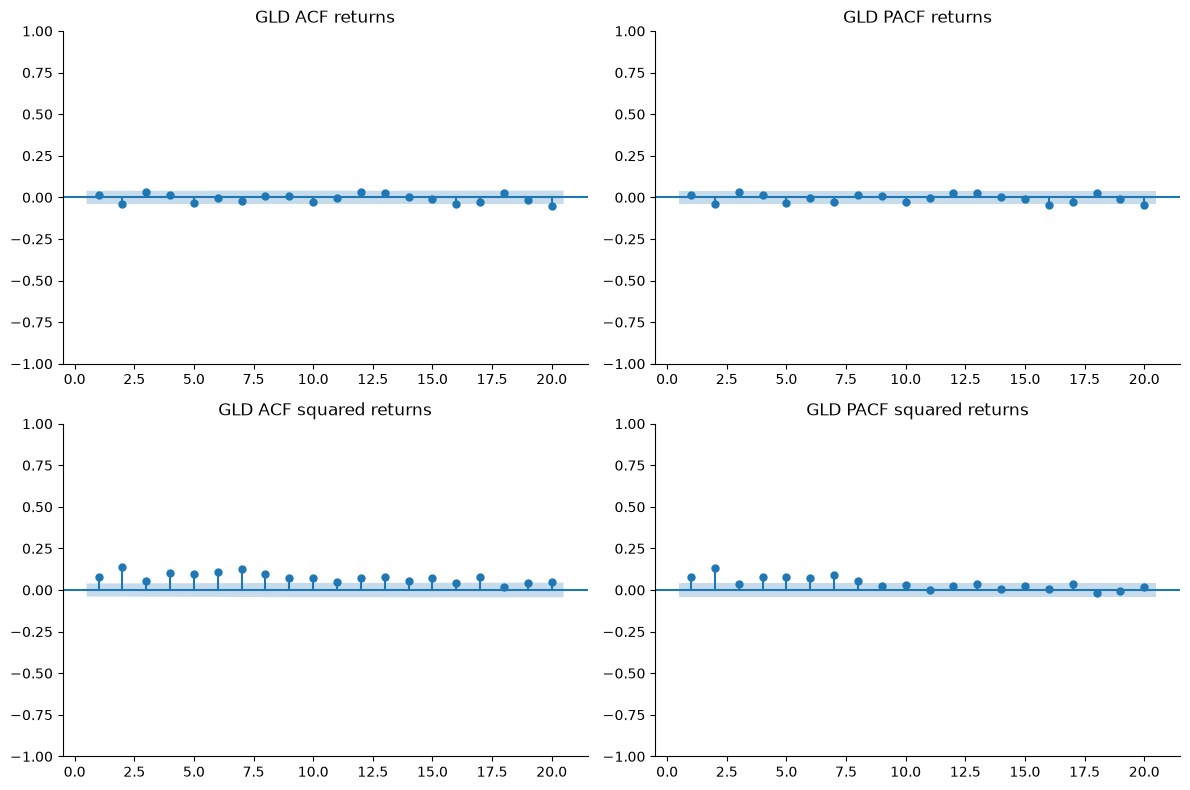

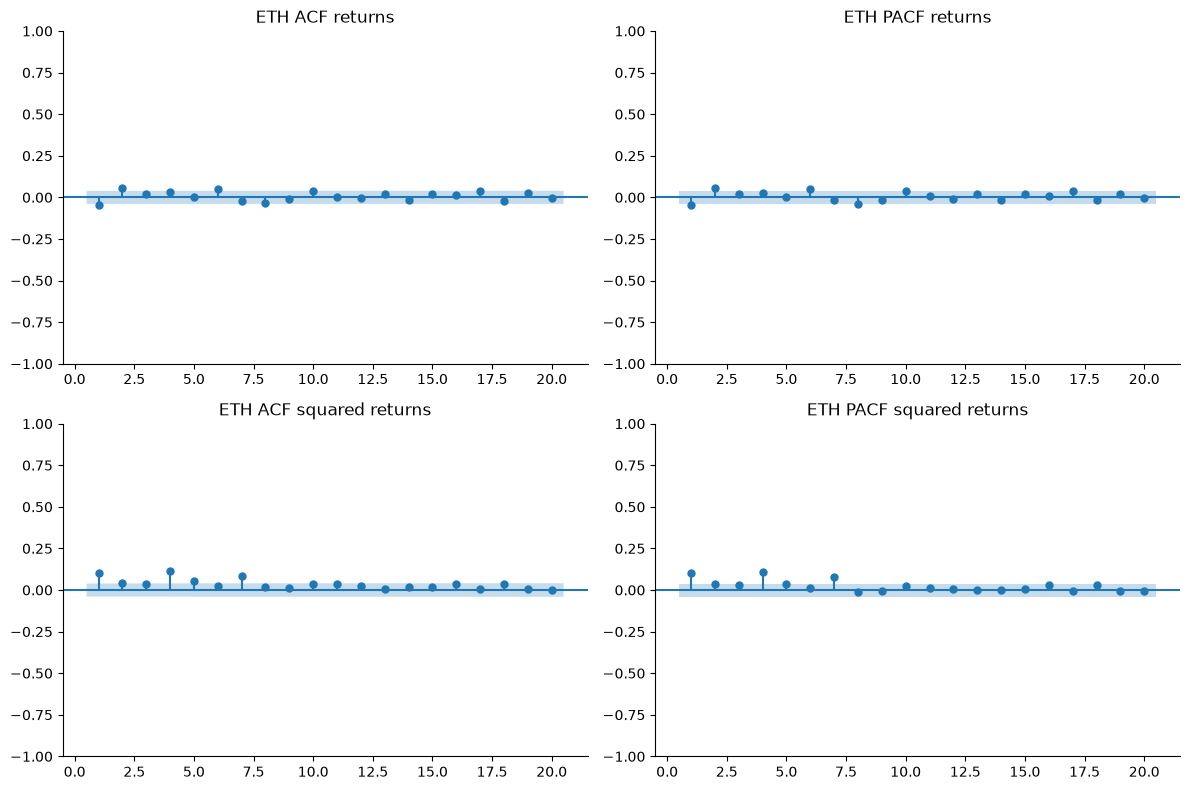

In [5]:
for a in CHOSEN:
    fig,axs=plt.subplots(2,2,figsize=(12,8))
    for row,(kind,y) in enumerate([('returns',train[a]),('squared returns',train[a]**2)]):
        plot_acf(y,lags=20,zero=False,ax=axs[row,0],title=a+' ACF '+kind)
        plot_pacf(y,lags=20,zero=False,method='ywm',ax=axs[row,1],title=a+' PACF '+kind)
    showfig(a+'_fingerprints')
    vals=acf(train[a],nlags=2);sq=acf(train[a]**2,nlags=2);band=1.96/np.sqrt(len(train[a]))
    interpretations['fingerprint_'+a]=f'{a} return ACF: lag 1={vals[1]:.4f}, lag 2={vals[2]:.4f}, approximate white-noise band ±{band:.4f}; a constant-only mean is the starting candidate, with AR(1), MA(1) and small ARMA alternatives checked by training BIC. The return PACF isolates direct lag effects after shorter lags; scattered spikes do not justify a large order. The squared-return ACF has lag 1={sq[1]:.4f}, indicating whether persistence in risk is stronger than in direction. The squared-return PACF is a variance fingerprint, motivating GARCH(1,1) rather than adding squared-return dynamics to the mean ARMA.'

for a in CHOSEN:
    band=1.96/np.sqrt(len(train[a]));ra=acf(train[a],nlags=20);rp=pacf(train[a],nlags=20,method='ywm');sa=acf(train[a]**2,nlags=20);sp=pacf(train[a]**2,nlags=20,method='ywm')
    interpretations['fingerprint_'+a]=f'{a}: training-only approximate white-noise band is ±{band:.4f}.\n\n- Return ACF: lags 1/2 are {ra[1]:+.4f}/{ra[2]:+.4f}; '+('both are inside the band, suggesting ARMA(0,0) as the starting candidate.' if max(abs(ra[1]),abs(ra[2]))<band else 'small early spikes motivate AR(1), MA(1), AR(2) or MA(2) candidates, not a large automatic order.')+f'\n- Return PACF: lags 1/2 are {rp[1]:+.4f}/{rp[2]:+.4f}; direct lag effects are checked against the small BIC grid rather than assumed forecastable.\n- Squared-return ACF: lag 1 is {sa[1]:+.4f}; dependence in squared returns motivates a conditional-variance model such as GARCH(1,1).\n- Squared-return PACF: lag 1 is {sp[1]:+.4f}; it describes direct variance dependence and is not the mean ARMA order. The full 20-lag pictures are shown above.'


GLD: training-only approximate white-noise band is ±0.0396.

- Return ACF: lags 1/2 are +0.0145/-0.0386; both are inside the band, suggesting ARMA(0,0) as the starting candidate.
- Return PACF: lags 1/2 are +0.0145/-0.0388; direct lag effects are checked against the small BIC grid rather than assumed forecastable.
- Squared-return ACF: lag 1 is +0.0759; dependence in squared returns motivates a conditional-variance model such as GARCH(1,1).
- Squared-return PACF: lag 1 is +0.0759; it describes direct variance dependence and is not the mean ARMA order. The full 20-lag pictures are shown above.

ETH: training-only approximate white-noise band is ±0.0391.

- Return ACF: lags 1/2 are -0.0442/+0.0556; small early spikes motivate AR(1), MA(1), AR(2) or MA(2) candidates, not a large automatic order.
- Return PACF: lags 1/2 are -0.0442/+0.0537; direct lag effects are checked against the small BIC grid rather than assumed forecastable.
- Squared-return ACF: lag 1 is +0.1009; dependence in squared returns motivates a conditional-variance model such as GARCH(1,1).
- Squared-return PACF: lag 1 is +0.1009; it describes direct variance dependence and is not the mean ARMA order. The full 20-lag pictures are shown above.

In [6]:
ORDER={};MODEL={};grids=[];diag_rows=[];GARCH={};grows=[]
for a in ASSETS:
    grid,best,res=select_arma(100*train[a]);ORDER[a]=(best[0],0,best[1]);MODEL[a]=res
    print(a,'training ΔBIC vs ARMA(0,0), winner',best);display(grid)
    for p in range(3):
        for q in range(3):grids.append({'asset':a,'p':p,'q':q,'delta_BIC':grid.loc[p,q],'winner':(p,q)==best})
    g=fit_garch(train[a]);GARCH[a]=g;params=g.params;pers=params['alpha[1]']+params['beta[1]']
    grows.append({'asset':a,'omega_pct2':params.omega,'alpha':params['alpha[1]'],'beta':params['beta[1]'],'persistence':pers,'half_life_observations':np.log(.5)/np.log(pers) if 0<pers<1 else np.inf,'nu':params.nu,'uncond_vol_pct_yr':np.sqrt(params.omega/(1-pers)*PPY[a]) if pers<1 else np.nan,'convergence_flag':g.convergence_flag})
    dr=diagnose_arma(res,ORDER[a]);standard=np.asarray(res.resid)/np.asarray(g.conditional_volatility)
    robust=acorr_ljungbox(standard,lags=[10],model_df=best[0]+best[1]).iloc[0]
    diag_rows.append({'asset':a,**dr,'standardized_LB_stat':robust.lb_stat,'standardized_LB_p':robust.lb_pvalue,'raw_reject_5pct':dr['LB(ε) p']<.05,'standardized_reject_5pct':robust.lb_pvalue<.05})
grid_all=pd.DataFrame(grids);save_table(grid_all,'task2_BIC_grid')
diag=pd.DataFrame(diag_rows).set_index('asset');save_table(diag,'task2_residual_trial')
gtable=pd.DataFrame(grows).set_index('asset');gtable.to_csv(OUTPUT/'results/task4_training_GARCH.csv')
ties=[]
for a in ASSETS:
    t=grid_all[grid_all.asset==a].sort_values('delta_BIC')
    for i in range(len(t)-1):
        u,v=t.iloc[i],t.iloc[i+1]
        if abs(v.delta_BIC-u.delta_BIC)<=2:ties.append(f'{a}: ARMA({u.p},{u.q}) and ARMA({v.p},{v.q}), ΔBIC difference {v.delta_BIC-u.delta_BIC:.3f}'+(' (includes the winner)' if u.winner or v.winner else ' (both behind the winner)'));break
changed=diag.index[diag.raw_reject_5pct!=diag.standardized_reject_5pct].tolist()
interpretations['bic']='Selected orders: '+', '.join(f'{a} ARMA({ORDER[a][0]},{ORDER[a][2]})' for a in ASSETS)+'. Near ties (within 2 BIC units): '+('; '.join(ties) if ties else 'none on this grid; I do not invent a tie')+'. Within two units the evidence from fit versus complexity is weak; I prefer parsimony and retain the preselected BIC winner rather than switching after test scores. The grid reports all nine candidates for every asset.'
interpretations['diag']='H0 for Ljung–Box: no residual serial correlation through lag 10, with p+q degrees-of-freedom adjustment. ARCH-LM H0: no ARCH effects through lag 10; JB H0: normality. Standardizing by training-only GARCH conditional volatility changes the 5% Ljung–Box verdict for '+(', '.join(changed) if changed else 'no assets')+'. Raw autocorrelations can be dominated by high-volatility observations, so dividing by conditional sigma can alter the test. This is the course\'s volatility-standardized sensitivity check, not a general proof of independence or a fully distribution-free robust portmanteau test.'


SPY training ΔBIC vs ARMA(0,0), winner (2, 2)


q (MA),0,1,2
p (AR),,,
0,0.000000,-23.738420,-26.789043
1,-27.462558,-24.355349,-19.655252
2,-26.621584,-18.822510,-114.489222


/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/homebrew/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


EUR/USD training ΔBIC vs ARMA(0,0), winner (0, 0)


q (MA),0,1,2
p (AR),,,
0,0.000000,7.726913,14.981209
1,7.730303,12.516401,20.039388
2,14.994448,20.037316,25.801879


...

q (MA),0,1,2
p (AR),,,
0,0.000000,7.241129,11.301282
1,7.285319,12.777446,18.224627
2,11.395056,17.954293,22.136969


ETH training ΔBIC vs ARMA(0,0), winner (0, 0)


q (MA),0,1,2
p (AR),,,
0,0.000000,3.407582,3.374292
1,2.916376,5.676175,8.057430
2,3.464371,7.812917,15.494730


,asset,p,q,delta_BIC,winner
0,SPY,0,0,0.000000,False
1,SPY,0,1,-23.738420,False
2,SPY,0,2,-26.789043,False
3,SPY,1,0,-27.462558,False
4,SPY,1,1,-24.355349,False
5,SPY,1,2,-19.655252,False
6,SPY,2,0,-26.621584,False
7,SPY,2,1,-18.822510,False
8,SPY,2,2,-114.489222,True
9,EUR/USD,0,0,0.000000,True


,LB(ε) p,LB(ε²) p,ARCH-LM p,JB p,kurtosis,standardized_LB_stat,standardized_LB_p,raw_reject_5pct,standardized_reject_5pct
asset,,,,,,,,,
SPY,0.028667,0.000000e+00,2.641659e-161,0.000000e+00,12.052511,32.097689,0.000016,True,True
EUR/USD,0.058015,1.584439e-48,1.825652e-24,8.050403e-154,5.580394,8.915833,0.540110,False,False
BTC,0.025097,4.893664e-28,1.948772e-20,0.000000e+00,14.525205,29.518085,0.001027,True,True
GLD,0.172255,2.018345e-43,3.082640e-23,1.032088e-180,5.835587,10.995869,0.357840,False,False
ETH,0.000818,6.426443e-17,8.718096e-13,0.000000e+00,14.047029,24.169404,0.007163,True,True


Selected orders: SPY ARMA(2,2), EUR/USD ARMA(0,0), BTC ARMA(0,0), GLD ARMA(0,0), ETH ARMA(0,0). Near ties (within 2 BIC units): SPY: ARMA(1,0) and ARMA(0,2), ΔBIC difference 0.674 (both behind the winner); EUR/USD: ARMA(0,1) and ARMA(1,0), ΔBIC difference 0.003 (both behind the winner); BTC: ARMA(1,0) and ARMA(0,1), ΔBIC difference 0.062 (both behind the winner); GLD: ARMA(0,1) and ARMA(1,0), ΔBIC difference 0.044 (both behind the winner); ETH: ARMA(1,0) and ARMA(0,2), ΔBIC difference 0.458 (both behind the winner). Within two units the evidence from fit versus complexity is weak; I prefer parsimony and retain the preselected BIC winner rather than switching after test scores. The grid reports all nine candidates for every asset.

H0 for Ljung–Box: no residual serial correlation through lag 10, with p+q degrees-of-freedom adjustment. ARCH-LM H0: no ARCH effects through lag 10; JB H0: normality. Standardizing by training-only GARCH conditional volatility changes the 5% Ljung–Box verdict for no assets. Raw autocorrelations can be dominated by high-volatility observations, so dividing by conditional sigma can alter the test. This is the course's volatility-standardized sensitivity check, not a general proof of independence or a fully distribution-free robust portmanteau test.

## Task 3 — Honest mean showdown
**DM H0:** equal expected squared-error loss, ARMA versus expanding mean. A statistically significant negative statistic favours ARMA; a significant positive statistic favours the mean; otherwise the result is a tie in evidence, not proof of equivalence. The zero forecast has no directional call, so hit rate is N/A. The coin-flip band is the course's approximate independent-Bernoulli 95% reference, shown alongside the realized always-up hit rate.

Parameters are fitted to observations strictly before each 63-observation block. The ARMA filter updates using earlier realized returns within the block; each one-step prediction is produced before its target. Holdout outcomes are allowed to enter later expanding-window refits, never their own forecasts.

Mean and variance walk-forward: SPY


Mean and variance walk-forward: EUR/USD


Mean and variance walk-forward: BTC


Mean and variance walk-forward: GLD


Mean and variance walk-forward: ETH


,asset,model,RMSE_pct,MAE_pct,hit_pct,coin_low_pct,coin_high_pct,up_days_pct,n
0,SPY,zero,1.044037,0.684366,NaN,45.568287,54.431713,55.419223,489
1,SPY,mean,1.042466,0.680464,55.419223,45.568287,54.431713,55.419223,489
2,SPY,ARMA,1.059677,0.700887,49.079755,45.568287,54.431713,55.419223,489
3,EUR/USD,zero,0.451366,0.328031,NaN,45.643369,54.356631,46.047431,506
4,EUR/USD,mean,0.451488,0.327882,53.754941,45.643369,54.356631,46.047431,506
5,EUR/USD,ARMA,0.451513,0.327844,53.754941,45.643369,54.356631,46.047431,506
6,BTC,zero,2.329302,1.635948,NaN,46.335008,53.664992,49.650350,715
7,BTC,mean,2.332100,1.643117,49.650350,46.335008,53.664992,49.650350,715
8,BTC,ARMA,2.332283,1.643334,49.650350,46.335008,53.664992,49.650350,715
9,GLD,zero,1.545181,1.106620,NaN,45.568287,54.431713,57.464213,489


,asset,H0,DM_stat,p,verdict
0,SPY,equal expected squared-error loss,0.641431,0.521243,tie / insufficient evidence
1,EUR/USD,equal expected squared-error loss,0.645423,0.518653,tie / insufficient evidence
2,BTC,equal expected squared-error loss,1.486979,0.137020,tie / insufficient evidence
3,GLD,equal expected squared-error loss,-0.622658,0.533510,tie / insufficient evidence
4,ETH,equal expected squared-error loss,1.852575,0.063943,tie / insufficient evidence


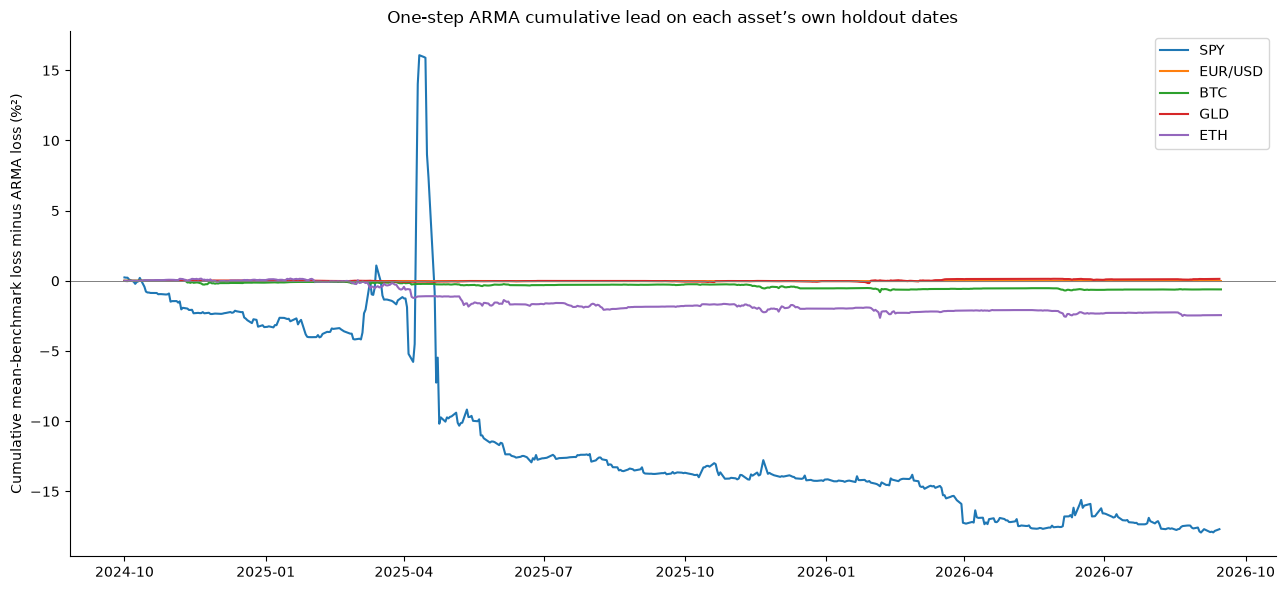

In [7]:
SHOW={};VOL={};DM={};score=[];dmrows=[]
for a in ASSETS:
    print('Mean and variance walk-forward:',a,flush=True)
    f=rolling_forecast(100*ret[a],ORDER[a],TEST_START,REFIT)/100
    S=pd.DataFrame({'actual':test[a],'zero':0.,'mean':ret[a].expanding().mean().shift(1).reindex(f.index),'ARMA':f})
    assert S.notna().all().all() and len(S)==len(test[a]);SHOW[a]=S
    for c in ['zero','mean','ARMA']:
        e=S.actual-S[c];band=1.96*50/np.sqrt(len(S))
        score.append({'asset':a,'model':c,'RMSE_pct':np.sqrt(np.mean(e**2))*100,'MAE_pct':np.mean(abs(e))*100,'hit_pct':np.nan if c=='zero' else np.mean(np.sign(S[c])==np.sign(S.actual))*100,'coin_low_pct':50-band,'coin_high_pct':50+band,'up_days_pct':100*np.mean(S.actual>0),'n':len(S)})
    t,p=dm_test((S.actual-S.ARMA)**2,(S.actual-S['mean'])**2);DM[a]=(t,p);dmrows.append({'asset':a,'H0':'equal expected squared-error loss','DM_stat':t,'p':p,'verdict':verdict(t,p)})
    r2=(100*ret[a])**2;gv=rolling_garch_variance(ret[a],TEST_START,REFIT)
    V=pd.DataFrame({'actual_r2':r2,'constant':r2.expanding().mean().shift(1),'rolling21':r2.rolling(21).mean().shift(1),'EWMA':r2.ewm(alpha=.06,adjust=False).mean().shift(1),'GARCH':gv}).loc[TEST_START:]
    assert V.notna().all().all() and (V.iloc[:,1:]>0).all().all();VOL[a]=V
    S.to_csv(OUTPUT/'results'/f'{a.replace("/","_")}_mean_forecasts.csv');V.to_csv(OUTPUT/'results'/f'{a.replace("/","_")}_variance_forecasts.csv')
score=pd.DataFrame(score);mean_dm=pd.DataFrame(dmrows);save_table(score,'task3_mean_scoreboard');save_table(mean_dm,'task3_mean_DM')
fig,ax=plt.subplots(figsize=(13,6))
for a in ASSETS:
    S=SHOW[a];lead=((S.actual-S['mean'])**2-(S.actual-S.ARMA)**2).cumsum()*1e4
    ax.plot(lead,label=a)
    interpretations['lead_'+a]=f'{a}: final cumulative lead is {lead.iloc[-1]:.4f} percent-squared units; positive means lower cumulative ARMA squared loss. The path\'s min/max are {lead.min():.4f}/{lead.max():.4f}; inspect reversals rather than treating a temporary lead as skill. DM statistic {DM[a][0]:+.3f}, p={DM[a][1]:.4g}, gives {verdict(*DM[a])} at 5%.'
ax.axhline(0,color='grey',lw=.7);ax.set_ylabel('Cumulative mean-benchmark loss minus ARMA loss (%²)');ax.legend();ax.set_title('One-step ARMA cumulative lead on each asset’s own holdout dates');showfig('task3_cumulative_lead')


SPY: final cumulative lead is -17.6923 percent-squared units; positive means lower cumulative ARMA squared loss. The path's min/max are -17.9302/16.0761; inspect reversals rather than treating a temporary lead as skill. DM statistic +0.641, p=0.5212, gives tie / insufficient evidence at 5%.

EUR/USD: final cumulative lead is -0.0114 percent-squared units; positive means lower cumulative ARMA squared loss. The path's min/max are -0.0243/0.0000; inspect reversals rather than treating a temporary lead as skill. DM statistic +0.645, p=0.5187, gives tie / insufficient evidence at 5%.

BTC: final cumulative lead is -0.6098 percent-squared units; positive means lower cumulative ARMA squared loss. The path's min/max are -0.8049/0.0360; inspect reversals rather than treating a temporary lead as skill. DM statistic +1.487, p=0.137, gives tie / insufficient evidence at 5%.

GLD: final cumulative lead is 0.1404 percent-squared units; positive means lower cumulative ARMA squared loss. The path's min/max are -0.1576/0.1476; inspect reversals rather than treating a temporary lead as skill. DM statistic -0.623, p=0.5335, gives tie / insufficient evidence at 5%.

ETH: final cumulative lead is -2.4420 percent-squared units; positive means lower cumulative ARMA squared loss. The path's min/max are -2.6357/0.1649; inspect reversals rather than treating a temporary lead as skill. DM statistic +1.853, p=0.06394, gives tie / insufficient evidence at 5%.

In [8]:
a='SPY';S=SHOW[a];last=ret[a].shift(1).reindex(S.index)
last_rmse=np.sqrt(np.mean((S.actual-last)**2))*100;mean_rmse=np.sqrt(np.mean((S.actual-S['mean'])**2))*100
trap=pd.DataFrame([{'asset':a,'yesterday_return_RMSE_pct':last_rmse,'expanding_mean_RMSE_pct':mean_rmse,'manufactured_improvement_pct':100*(1-mean_rmse/last_rmse),'iid_limit_improvement_pct':100*(1-1/np.sqrt(2))}]);save_table(trap,'task3_sqrt2_trap')
interpretations['trap']=f'The expanding mean reduces SPY RMSE from {last_rmse:.5f}% against yesterday\'s return to {mean_rmse:.5f}%, an apparent {100*(1-mean_rmse/last_rmse):.2f}% improvement. For independent zero-mean returns, the last-value forecast adds yesterday\'s unrelated shock, raising expected error variance from σ² to 2σ². Consequently a constant gets a theoretical 29.29% advantage without predicting anything; the honest comparison is against zero and the expanding mean, followed by DM.'
for a in CHOSEN:
    z=score[(score.asset==a)&(score.model=='ARMA')].iloc[0];m=score[(score.asset==a)&(score.model=='mean')].iloc[0];t,p=DM[a]
    gross=np.sign(SHOW[a].ARMA)*SHOW[a].actual
    net=gross-.0005 # a simple illustration charges 5bp for every one-period trade, no zero positions
    interpretations['mean_'+a]=f'{a}: ARMA RMSE {z.RMSE_pct:.5f}% versus expanding mean {m.RMSE_pct:.5f}%, a gain of {(m.RMSE_pct-z.RMSE_pct)*100:.3f} basis points in RMSE; H0 equal expected loss, DM={t:+.3f}, p={p:.4g}, so the 5% verdict is {verdict(t,p)}. '+('The holdout supports lower ARMA loss, not a guaranteed profitable strategy.' if t<0 and p<.05 else 'I do not claim a forecastable mean beyond this benchmark on this holdout.')+f' A 5bp cost is 0.05 return percentage points per trade; RMSE reduction is not trading profit. As an explicitly illustrative daily sign strategy with a cost on every trade, mean net log return is {net.mean()*10000:.3f}bp and gross is {gross.mean()*10000:.3f}bp per observation; execution, position sizing and turnover would need their own sealed strategy test.'
# Daily-refit sensitivity is diagnostic only; it does not replace the predeclared primary protocol.
a='GLD';fd=rolling_forecast(100*ret[a],ORDER[a],TEST_START,1)/100
S=SHOW[a];dq=np.sqrt(np.mean((S.actual-S.ARMA)**2))*100;dd=np.sqrt(np.mean((S.actual-fd)**2))*100
daily=pd.DataFrame([{'asset':a,'quarterly_RMSE_pct':dq,'daily_RMSE_pct':dd,'difference_RMSE_pp':dd-dq,'max_forecast_difference_decimal':np.max(abs(fd-S.ARMA))}]);save_table(daily,'task3_daily_refit_sensitivity')
interpretations['daily']=f'For GLD, refitting every observation changes RMSE from {dq:.6f}% to {dd:.6f}% (daily minus 63-observation cadence = {dd-dq:+.6f} percentage points). This is a requested sensitivity experiment; I retain quarterly-observation refits as the primary result and do not pick whichever cadence scores better after viewing the holdout.'


,asset,yesterday_return_RMSE_pct,expanding_mean_RMSE_pct,manufactured_improvement_pct,iid_limit_improvement_pct
0,SPY,1.543294,1.042466,32.4519,29.289322


,asset,quarterly_RMSE_pct,daily_RMSE_pct,difference_RMSE_pp,max_forecast_difference_decimal
0,GLD,1.543472,1.543565,0.000093,0.000076


The expanding mean reduces SPY RMSE from 1.54329% against yesterday's return to 1.04247%, an apparent 32.45% improvement. For independent zero-mean returns, the last-value forecast adds yesterday's unrelated shock, raising expected error variance from σ² to 2σ². Consequently a constant gets a theoretical 29.29% advantage without predicting anything; the honest comparison is against zero and the expanding mean, followed by DM.

GLD: ARMA RMSE 1.54347% versus expanding mean 1.54356%, a gain of 0.009 basis points in RMSE; H0 equal expected loss, DM=-0.623, p=0.5335, so the 5% verdict is tie / insufficient evidence. I do not claim a forecastable mean beyond this benchmark on this holdout. A 5bp cost is 0.05 return percentage points per trade; RMSE reduction is not trading profit. As an explicitly illustrative daily sign strategy with a cost on every trade, mean net log return is 4.818bp and gross is 9.818bp per observation; execution, position sizing and turnover would need their own sealed strategy test.

ETH: ARMA RMSE 3.63594% versus expanding mean 3.63547%, a gain of -0.047 basis points in RMSE; H0 equal expected loss, DM=+1.853, p=0.06394, so the 5% verdict is tie / insufficient evidence. I do not claim a forecastable mean beyond this benchmark on this holdout. A 5bp cost is 0.05 return percentage points per trade; RMSE reduction is not trading profit. As an explicitly illustrative daily sign strategy with a cost on every trade, mean net log return is -5.716bp and gross is -0.716bp per observation; execution, position sizing and turnover would need their own sealed strategy test.

For GLD, refitting every observation changes RMSE from 1.543472% to 1.543565% (daily minus 63-observation cadence = +0.000093 percentage points). This is a requested sensitivity experiment; I retain quarterly-observation refits as the primary result and do not pick whichever cadence scores better after viewing the holdout.

## Task 4 — Variance showdown, fan charts and Forecast Eval Suite v1.0
GARCH parameters are estimated in percent-return units: omega is %², alpha/beta are dimensionless. Persistence and half-life are measured per observation; crypto observations are calendar days, ETF/FX observations trading days. Unconditional volatility is defined only if alpha+beta<1. **QLIKE DM H0:** equal expected loss for GARCH and the stated benchmark, using the same dates and the same positive squared-return proxy.

In [9]:
save_table(gtable,'task4_training_GARCH')
vrows=[];vdrows=[]
for a in ASSETS:
    V=VOL[a];loss={c:qlike(V[c],V.actual_r2) for c in V.columns[1:]}
    for c,l in loss.items():vrows.append({'asset':a,'model':c,'QLIKE':l.mean(),'n':len(V)})
    for c in ['constant','rolling21','EWMA']:
        t,p=dm_test(loss['GARCH'],loss[c]);vdrows.append({'asset':a,'benchmark':c,'H0':'equal expected QLIKE','DM_stat':t,'p':p,'verdict':verdict(t,p)})
vscore=pd.DataFrame(vrows);vDM=pd.DataFrame(vdrows);save_table(vscore,'task4_variance_scoreboard');save_table(vDM,'task4_variance_DM')
notbeat=vDM[(vDM.benchmark=='constant')&~((vDM.DM_stat<0)&(vDM.p<.05))].asset.tolist()
interpretations['garch']='Training persistence α+β: '+', '.join(f'{a} {gtable.loc[a,"persistence"]:.5f}' for a in ASSETS)+'. Higher persistence means a slower decay of shocks, but equal observation half-lives mean different elapsed time on trading versus crypto calendars. The table compares the low-volatility currency/equity/gold series with the high-volatility crypto series; levels of volatility and persistence are distinct quantities. Infinite half-life or N/A unconditional volatility is reported explicitly at or above the stationarity boundary.'
interpretations['vol']='GARCH does not beat the expanding constant benchmark at the two-sided 5% DM threshold for '+(', '.join(notbeat) if notbeat else 'no assets in this sample')+'. For every such asset, the Risk Agent falls back to the expanding historical squared-return level rather than claiming validated GARCH risk improvement. The three comparisons per asset are displayed separately: success versus a constant does not imply success versus rolling-21 or EWMA. No multiplicity adjustment is imposed because the brief specifies per-comparison 5%; these repeated tests should not be interpreted as a family-wide guarantee.'


,omega_pct2,alpha,beta,persistence,half_life_observations,nu,uncond_vol_pct_yr,convergence_flag
asset,,,,,,,,
SPY,0.020054,0.176834,0.819833,0.996667,207.614645,5.919673,38.938637,0
EUR/USD,0.000985,0.025124,0.970075,0.995200,144.050368,7.779430,7.189392,0
BTC,0.165429,0.104907,0.895093,1.000000,inf,3.164919,NaN,0
GLD,0.010631,0.038059,0.948869,0.986928,52.678444,5.748526,14.315975,0
ETH,0.393910,0.100826,0.899174,1.000000,inf,3.351350,NaN,0


,asset,model,QLIKE,n
0,SPY,constant,1.949636,489
1,SPY,rolling21,1.805900,489
2,SPY,EWMA,1.727284,489
3,SPY,GARCH,1.658972,489
4,EUR/USD,constant,1.627602,506
5,EUR/USD,rolling21,1.637732,506
6,EUR/USD,EWMA,1.543550,506
7,EUR/USD,GARCH,1.536185,506
8,BTC,constant,2.155260,715
9,BTC,rolling21,1.912841,715


,asset,benchmark,H0,DM_stat,p,verdict
0,SPY,constant,equal expected QLIKE,-1.572495,1.158359e-01,tie / insufficient evidence
1,SPY,rolling21,equal expected QLIKE,-2.293799,2.180202e-02,better
2,SPY,EWMA,equal expected QLIKE,-1.914747,5.552484e-02,tie / insufficient evidence
3,EUR/USD,constant,equal expected QLIKE,-2.032744,4.207840e-02,better
4,EUR/USD,rolling21,equal expected QLIKE,-1.761555,7.814448e-02,tie / insufficient evidence
5,EUR/USD,EWMA,equal expected QLIKE,-0.296315,7.669899e-01,tie / insufficient evidence
6,BTC,constant,equal expected QLIKE,-7.380641,1.575287e-13,better
7,BTC,rolling21,equal expected QLIKE,-1.649398,9.906606e-02,tie / insufficient evidence
8,BTC,EWMA,equal expected QLIKE,-0.639379,5.225763e-01,tie / insufficient evidence
9,GLD,constant,equal expected QLIKE,-2.624410,8.679928e-03,better


Training persistence α+β: SPY 0.99667, EUR/USD 0.99520, BTC 1.00000, GLD 0.98693, ETH 1.00000. Higher persistence means a slower decay of shocks, but equal observation half-lives mean different elapsed time on trading versus crypto calendars. The table compares the low-volatility currency/equity/gold series with the high-volatility crypto series; levels of volatility and persistence are distinct quantities. Infinite half-life or N/A unconditional volatility is reported explicitly at or above the stationarity boundary.

GARCH does not beat the expanding constant benchmark at the two-sided 5% DM threshold for SPY, ETH. For every such asset, the Risk Agent falls back to the expanding historical squared-return level rather than claiming validated GARCH risk improvement. The three comparisons per asset are displayed separately: success versus a constant does not imply success versus rolling-21 or EWMA. No multiplicity adjustment is imposed because the brief specifies per-comparison 5%; these repeated tests should not be interpreted as a family-wide guarantee.

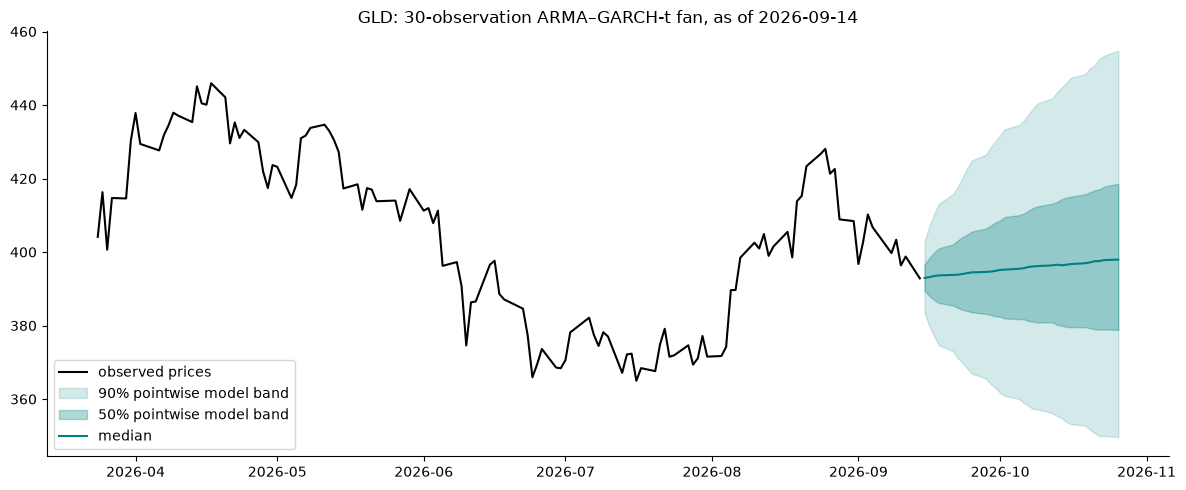

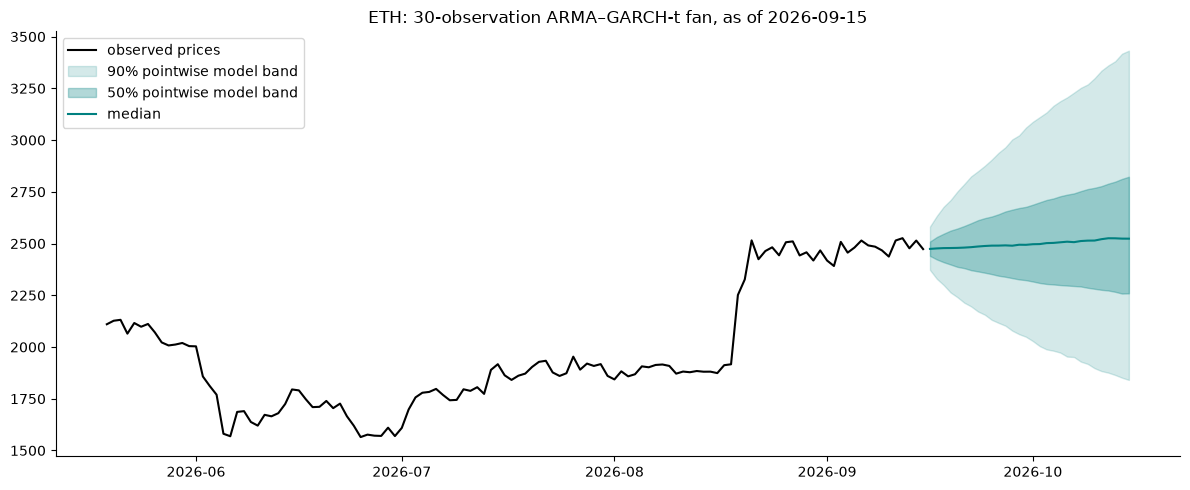

In [10]:
def fan_chart(a,H=30,N=10000,seed=4204):
    r=ret[a];m=ARIMA(100*r.values,order=ORDER[a],trend='c').fit();g=fit_garch(r);gp=g.params
    # Propagate stochastic ARMA dynamics, not just a deterministic mean path.
    mu=float(m.params[m.param_names.index('const')]);ars=np.asarray(m.arparams);mas=np.asarray(m.maparams)
    P,Q=len(ars),len(mas);hist_y=[np.full(N,100*r.values[-i-1]) for i in range(P)]
    hist_e=[np.full(N,np.asarray(m.resid)[-i-1]) for i in range(Q)]
    sig=np.full(N,g.conditional_volatility.iloc[-1]**2);prev=np.full(N,g.resid.iloc[-1]);rng=np.random.default_rng(seed)
    logp=np.zeros((N,H));z=rng.standard_t(gp.nu,(N,H))/np.sqrt(gp.nu/(gp.nu-2))
    for h in range(H):
        sig=gp.omega+gp['alpha[1]']*prev**2+gp['beta[1]']*sig;e=np.sqrt(sig)*z[:,h]
        y=np.full(N,mu)+sum((ars[j]*(hist_y[j]-mu) for j in range(P)),start=np.zeros(N))+sum((mas[j]*hist_e[j] for j in range(Q)),start=np.zeros(N))+e
        logp[:,h]=(logp[:,h-1] if h else 0)+y/100
        hist_y=([y]+hist_y)[:P];hist_e=([e]+hist_e)[:Q];prev=e
    paths=prices[a].iloc[-1]*np.exp(logp);qs=np.percentile(paths,[5,25,50,75,95],axis=0)
    dates=pd.date_range(prices[a].index[-1],periods=H+1,freq='D' if PPY[a]==365 else 'B')[1:]
    fig,ax=plt.subplots(figsize=(12,5));ax.plot(prices[a].iloc[-120:],color='black',label='observed prices');ax.fill_between(dates,qs[0],qs[4],alpha=.17,color='teal',label='90% pointwise model band');ax.fill_between(dates,qs[1],qs[3],alpha=.3,color='teal',label='50% pointwise model band');ax.plot(dates,qs[2],color='teal',label='median');ax.legend();ax.set_title(f'{a}: 30-observation ARMA–GARCH-t fan, as of {prices[a].index[-1].date()}');showfig(a+'_30day_fan')
    frame=pd.DataFrame(qs.T,index=dates,columns=['p05','p25','median','p75','p95']);frame.to_csv(OUTPUT/'results'/f'{a}_fan_quantiles.csv')
    return frame,paths
FANS={}
for a in CHOSEN:
    frame,paths=fan_chart(a);FANS[a]=frame
    interpretations['fan_'+a]=f'The 90% model-based day-30 band for {a} is [{frame.p05.iloc[-1]:,.2f}, {frame.p95.iloc[-1]:,.2f}], in the price series\'s quote units, as of {prices[a].index[-1].date()}. I quote the median, {frame["median"].iloc[-1]:,.2f}, rather than a mean: exponentiation creates right-skewed prices, and untruncated Student-t log shocks have no finite exponential moment, so a finite simulation mean is not a well-defined population price expectation. These are pointwise predictive quantiles conditional on fitted parameters, not simultaneous path coverage or parameter-uncertainty intervals. The horizon is 30 trading observations for GLD and 30 calendar days for ETH; the ETF future calendar is an approximate business-day index, not an exchange-holiday guarantee. This is a historical-as-of fan, not a forecast made with October 2026 information. The variance DM result versus constant is '+verdict(*tuple(vDM[(vDM.asset==a)&(vDM.benchmark=='constant')][['DM_stat','p']].iloc[0]))+'; where the risk gate fails, the GARCH fan is an educational model illustration and the Risk Agent must use the constant fallback.'


The 90% model-based day-30 band for GLD is [349.66, 454.79], in the price series's quote units, as of 2026-09-14. I quote the median, 397.94, rather than a mean: exponentiation creates right-skewed prices, and untruncated Student-t log shocks have no finite exponential moment, so a finite simulation mean is not a well-defined population price expectation. These are pointwise predictive quantiles conditional on fitted parameters, not simultaneous path coverage or parameter-uncertainty intervals. The horizon is 30 trading observations for GLD and 30 calendar days for ETH; the ETF future calendar is an approximate business-day index, not an exchange-holiday guarantee. This is a historical-as-of fan, not a forecast made with October 2026 information. The variance DM result versus constant is better; where the risk gate fails, the GARCH fan is an educational model illustration and the Risk Agent must use the constant fallback.

The 90% model-based day-30 band for ETH is [1,840.87, 3,432.13], in the price series's quote units, as of 2026-09-15. I quote the median, 2,523.59, rather than a mean: exponentiation creates right-skewed prices, and untruncated Student-t log shocks have no finite exponential moment, so a finite simulation mean is not a well-defined population price expectation. These are pointwise predictive quantiles conditional on fitted parameters, not simultaneous path coverage or parameter-uncertainty intervals. The horizon is 30 trading observations for GLD and 30 calendar days for ETH; the ETF future calendar is an approximate business-day index, not an exchange-holiday guarantee. This is a historical-as-of fan, not a forecast made with October 2026 information. The variance DM result versus constant is tie / insufficient evidence; where the risk gate fails, the GARCH fan is an educational model illustration and the Risk Agent must use the constant fallback.

### Explicit rules and thresholds
| Rule | Executable threshold | Justification |
|---|---|---|
| F1 entrance | ADF p<0.05 and KPSS p>=0.05 on training returns | Require agreement of opposite-null tests before extrapolating a stationary mean. |
| F2 information set | Every target's estimation end and data origin are strictly before its date; order selected before holdout | A target must not influence its own forecast or order choice. |
| F3 residual mean | GARCH-standardized Ljung–Box(10) p>=0.05, df=10−p−q | Volatility normalization is the course sensitivity check for residual serial correlation. |
| F4 incremental mean claim | DM p<0.05 and statistic<0 versus expanding mean | Claim incremental mean predictability only with holdout evidence. |
| R1 variance claim | QLIKE DM p<0.05 and statistic<0 versus expanding constant | Validate risk forecasting against the free benchmark. |
| R2 finite unconditional variance | alpha+beta<=0.995 and nu>2.05 | A 0.005 stationarity margin limits almost-integrated fits; nu margin keeps shock variance finite. Policy margin, not universal critical value. |
| F5 holdout length | n>=252 per asset | At least one trading year provides a basic evaluation floor; it does not guarantee DM power. |
| R3 calibration | Mincer–Zarnowitz HAC joint Wald p>=0.05 for intercept=0,slope=1 | Detect gross bias in squared-return calibration; non-rejection is not proof of calibration. |
| F6 directional claim | hit above upper coin-flip band and above realized up-day share | Avoid “above 50%” claims that ignore sampling noise or unconditional market direction. |
| F7 metric and benchmark hygiene | loss is squared error/MAE or QLIKE; return benchmark is zero/expanding mean; finite forecasts and positive variance | Reject MAPE and last-return benchmark tricks. |
| F8 fitting integrity | no GARCH optimizer failure in training and finite forecast arrays | A numerical failure is not evidence of forecasting skill. |

F4/F6 are permissions for stronger claims, not requirements to invent a signal. Their FAIL states imply using the benchmark or making no directional claim. R2/R3 are risk review gates in addition to the required constant-benchmark DM test.

In [11]:
PROTOCOL={'benchmarks':['zero','expanding_mean'],'mean_loss':'squared_error','variance_loss':'QLIKE'}
def metric_hygiene(protocol,S,V):
    return protocol['benchmarks']==['zero','expanding_mean'] and protocol['mean_loss']=='squared_error' and protocol['variance_loss']=='QLIKE' and np.isfinite(S.to_numpy()).all() and np.isfinite(V.to_numpy()).all() and (V.iloc[:,1:]>0).all().all()
def audit_forecast_v1(a):
    S=SHOW[a];V=VOL[a];gr=gtable.loc[a];de=diag.loc[a];ex=stationarity_exam(train[a]);mt,mp=DM[a]
    vv=vDM[(vDM.asset==a)&(vDM.benchmark=='constant')].iloc[0]
    # Origin and refit endpoints are explicit rather than the lecturer's hard-coded True.
    idx=ret[a].index;t0=int(np.searchsorted(idx,TEST_START));targets=np.arange(t0,len(idx));starts=t0+((targets-t0)//REFIT)*REFIT
    origins=idx[targets-1];estimation_ends=idx[starts-1];target_dates=idx[targets]
    gate=bool((origins<target_dates).all() and (estimation_ends<target_dates).all() and train[a].index.max()<TEST_START)
    mz=sm.OLS(V.actual_r2,sm.add_constant(V.GARCH)).fit(cov_type='HAC',cov_kwds={'maxlags':int(np.floor(4*(len(V)/100)**(2/9)))})
    wr=mz.wald_test((np.eye(2),np.array([0.,1.])),scalar=True);mz_p=float(wr.pvalue)
    hit=np.mean(np.sign(S.ARMA)==np.sign(S.actual));band=.5+1.96*.5/np.sqrt(len(S));up=(S.actual>0).mean()
    rules=[('F1 entrance',ex['verdict'].startswith('stationary'),'BLOCK'),('F2 sealed information set',gate,'BLOCK'),('F3 standardized residuals',de.standardized_LB_p>=.05,'REVIEW'),('F4 incremental mean',mp<.05 and mt<0,'CLAIM'),('R1 variance beats constant',vv.p<.05 and vv.DM_stat<0,'RISK'),('R2 persistence and t moments',gr.persistence<=.995 and gr.nu>2.05,'RISK'),('F5 minimum holdout',len(S)>=252,'BLOCK'),('R3 MZ calibration',mz_p>=.05,'REVIEW'),('F6 directional evidence',hit>band and hit>up,'CLAIM'),('F7 metric hygiene',metric_hygiene(PROTOCOL,S,V),'BLOCK'),('F8 training fit converged',gr.convergence_flag==0,'BLOCK')]
    return pd.DataFrame([{'asset':a,'rule':name,'pass':bool(ok),'status':'PASS' if ok else 'FAIL','scope':scope,'MZ_joint_p':mz_p if name.startswith('R3') else np.nan} for name,ok,scope in rules])
# Reuse the original course audit with these main variables; display its F1–F4/R1 beside the extension.
course_ns.update({'ASSETS':ASSETS,'train':train,'MODEL':MODEL,'ORDER':ORDER,'SHOW':{a:SHOW[a] for a in ASSETS},'DM':DM,'VOL':{a:{'dm':{'constant':tuple(vDM[(vDM.asset==a)&(vDM.benchmark=='constant')][['DM_stat','p']].iloc[0])}} for a in ASSETS}})
for a in ASSETS:course_ns['audit_forecast'](a)
evals=pd.concat([audit_forecast_v1(a) for a in ASSETS],ignore_index=True);save_table(evals.pivot(index='asset',columns='rule',values='status'),'task4_eval_report');evals.to_csv(OUTPUT/'results/task4_eval_long.csv',index=False)
# Substantive negative control: altering a future observation cannot alter earlier mean/variance predictions.
a='SPY';short=ret[a].iloc[:int(np.searchsorted(ret[a].index,TEST_START))+70].copy();alter=short.copy();alter.iloc[-1]+=1.
f1=rolling_forecast(100*short,ORDER[a],TEST_START,REFIT)/100;f2=rolling_forecast(100*alter,ORDER[a],TEST_START,REFIT)/100
v1=rolling_garch_variance(short,TEST_START,REFIT);v2=rolling_garch_variance(alter,TEST_START,REFIT)
np.testing.assert_allclose(f1,f2,rtol=1e-10,atol=1e-12);np.testing.assert_allclose(v1,v2,rtol=1e-10,atol=1e-12)
assert 100*(1-1/np.sqrt(2))>29 # analytic benchmark negative control
print('Future-target perturbation: mean and variance forecasts unchanged, PASS. Wrong-benchmark artificial-skill control: PASS.')
interpretations['eval']='The original course audit is displayed before the eleven-rule extension. FAIL under F4 or F6 blocks an incremental-mean or directional claim; it does not invalidate honest benchmark reporting. FAIL under R1 requires the expanding constant fallback. '+', '.join(a+': '+str((evals[evals.asset==a]['pass']).sum())+'/11 assertions pass' for a in ASSETS)+'. The future-target perturbation confirms that a modified last outcome leaves predictions for all evaluated targets unchanged, including its own one-step forecast. Training diagnostics and full-sample production fan fitting remain separate from holdout model selection.'

assert not metric_hygiene({**PROTOCOL,'benchmarks':['last_return']},SHOW['SPY'],VOL['SPY'])
print('Last-value return benchmark tripwire: PASS (illegal benchmark rejected).')


ANALYST AGENT — forecast eval rules v0.1 on SPY   (train 2,451 / test 489 days)
  ✅ PASS  F1 entrance exam: ADF rejects and KPSS does not (5%)
  ✅ PASS  F2 sealed holdout declared before any fit; metrics out-of-sample
  ❌ FAIL  F3 ARMA residuals are white noise (Ljung–Box(10) p > 0.05)
  ❌ FAIL  F4 ARMA beats the expanding mean (DM p < 0.05, t < 0)
  ❌ FAIL  R1 GARCH beats the constant variance by QLIKE (DM p < 0.05, t < 0)
           ↳ ARMA(2, 0, 2): RMSE 1.060% vs mean 1.042%;  DM t = +0.64;  GARCH vs constant DM t = -1.57
VERDICT  mean forecast      : NOT reportable → memo says 'no forecastable mean'; report the benchmark
         volatility forecast: REJECTED → fall back to the historical variance 

ANALYST AGENT — forecast eval rules v0.1 on EUR/USD   (train 2,539 / test 506 days)
  ✅ PASS  F1 entrance exam: ADF rejects and KPSS does not (5%)
  ✅ PASS  F2 sealed holdout declared before any fit; metrics out-of-sample
  ✅ PASS  F3 ARMA residuals are white noise (Ljung–Box(10) p > 0.

rule,F1 entrance,F2 sealed information set,F3 standardized residuals,F4 incremental mean,F5 minimum holdout,F6 directional evidence,F7 metric hygiene,F8 training fit converged,R1 variance beats constant,R2 persistence and t moments,R3 MZ calibration
asset,,,,,,,,,,,
BTC,PASS,PASS,FAIL,FAIL,PASS,FAIL,PASS,PASS,PASS,FAIL,FAIL
ETH,PASS,PASS,FAIL,FAIL,PASS,FAIL,PASS,PASS,FAIL,FAIL,FAIL
EUR/USD,PASS,PASS,PASS,FAIL,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS
GLD,PASS,PASS,PASS,FAIL,PASS,FAIL,PASS,PASS,PASS,PASS,PASS
SPY,PASS,PASS,FAIL,FAIL,PASS,FAIL,PASS,PASS,FAIL,FAIL,PASS


Future-target perturbation: mean and variance forecasts unchanged, PASS. Wrong-benchmark artificial-skill control: PASS.
Last-value return benchmark tripwire: PASS (illegal benchmark rejected).


The original course audit is displayed before the eleven-rule extension. FAIL under F4 or F6 blocks an incremental-mean or directional claim; it does not invalidate honest benchmark reporting. FAIL under R1 requires the expanding constant fallback. SPY: 6/11 assertions pass, EUR/USD: 8/11 assertions pass, BTC: 6/11 assertions pass, GLD: 9/11 assertions pass, ETH: 5/11 assertions pass. The future-target perturbation confirms that a modified last outcome leaves predictions for all evaluated targets unchanged, including its own one-step forecast. Training diagnostics and full-sample production fan fitting remain separate from holdout model selection.

### Behavioral coda (6 sentences)
A trader who sees a precise price target may mistake a conditional median for a guaranteed destination, whereas my band-first fan paragraphs show the range of plausible outcomes. A client may also read a positive centre as evidence of skill even when the displayed mean DM test fails to reject equal loss. Overconfidence narrows subjective “90%” intervals until they can cover the eventual outcome far less often, so I do not call these simulated bands empirically calibrated without coverage evidence. Hindsight bias makes the realized path look inevitable and invites moving the holdout or changing the chosen order after the event. An agent trained on published forecasts can inherit both biases if it learns from successful targets while ignoring misses and discarded models. The fixed split, the benchmark-specific DM statistic and the first-sentence 90% band keep the memo accountable to uncertainty and to what the models actually demonstrated.

## Optional bonus — ETH/BTC cointegration
ETH and BTC have an economic reason to co-move as crypto assets, but correlation of nonstationary prices does not establish a stable spread. I test the fixed pair on the training calendar only so this optional strategy seed does not tune the sealed forecast holdout. **ADF H0:** unit root in each log price. **Engle–Granger H0:** no cointegration; I use `coint()` with its residual-regression critical values, not ordinary univariate ADF critical values.

/var/folders/hs/tyt14plx5q1gc63938t8vvdm0000gn/T/ipykernel_27980/797643484.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pair=pd.concat([np.log(prices['ETH']).rename('ETH'),np.log(prices['BTC']).rename('BTC')],axis=1).dropna().loc[lambda d:d.index<TEST_START]


,pair,ETH_ADF_p,BTC_ADF_p,EG_stat,EG_p,EG_5pct_critical,hedge_ratio,spread_AR1_phi,half_life_observations,cointegrated_5pct
0,ETH/BTC,0.743491,0.757498,-2.354379,0.346755,-3.338559,1.263502,0.997278,254.292819,False


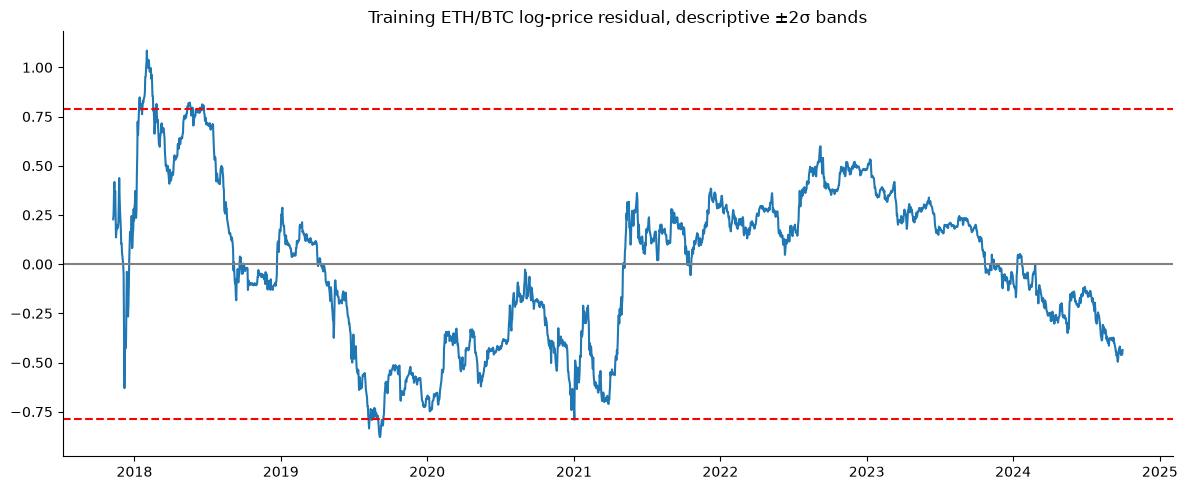

In [12]:
pair=pd.concat([np.log(prices['ETH']).rename('ETH'),np.log(prices['BTC']).rename('BTC')],axis=1).dropna().loc[lambda d:d.index<TEST_START]
ep=adfuller(pair.ETH,autolag='AIC')[1];bp=adfuller(pair.BTC,autolag='AIC')[1]
cstat,cp,crit=coint(pair.ETH,pair.BTC,trend='c',autolag='aic');fit=sm.OLS(pair.ETH,sm.add_constant(pair.BTC)).fit();spread=fit.resid
ar=sm.OLS(spread.iloc[1:].to_numpy(),sm.add_constant(spread.iloc[:-1].to_numpy())).fit();phi=ar.params[1]
half=np.log(.5)/np.log(abs(phi)) if 0<abs(phi)<1 else np.nan
coin=pd.DataFrame([{'pair':'ETH/BTC','ETH_ADF_p':ep,'BTC_ADF_p':bp,'EG_stat':cstat,'EG_p':cp,'EG_5pct_critical':crit[1],'hedge_ratio':fit.params.BTC,'spread_AR1_phi':phi,'half_life_observations':half,'cointegrated_5pct':cp<.05}]);save_table(coin,'bonus_cointegration')
fig,ax=plt.subplots(figsize=(12,5));ax.plot(spread);ax.axhline(0,color='grey');ax.axhline(2*spread.std(),ls='--',color='red');ax.axhline(-2*spread.std(),ls='--',color='red');ax.set_title('Training ETH/BTC log-price residual, descriptive ±2σ bands');showfig('bonus_ETH_BTC_spread')
interpretations['bonus']=f'ADF H0 unit root: ETH p={ep:.4g}, BTC p={bp:.4g}. Engle–Granger H0 no cointegration: statistic {cstat:.4f}, 5% critical value {crit[1]:.4f}, p={cp:.4g}; '+('the null is rejected at 5%, supporting a stationary residual for this training sample.' if cp<.05 else 'the null is not rejected at 5%, so I do not claim a validated mean-reverting spread.')+f' The descriptive AR(1) phi is {phi:.5f}, with half-life {half:.2f} observations; this is not evidence of cointegration on its own. A candidate rule would use the training hedge ratio to trade deviations beyond ±2 spread standard deviations and exit near zero. It would require independent forward testing, transaction costs and limits on loss and hedge-ratio drift. '+('The cointegration finding makes it a research candidate, not a demonstrated profitable trade.' if cp<.05 else 'Because cointegration is not supported here, the proposed rule remains a rejected research idea rather than an authorized trading signal.')


ADF H0 unit root: ETH p=0.7435, BTC p=0.7575. Engle–Granger H0 no cointegration: statistic -2.3544, 5% critical value -3.3386, p=0.3468; the null is not rejected at 5%, so I do not claim a validated mean-reverting spread. The descriptive AR(1) phi is 0.99728, with half-life 254.29 observations; this is not evidence of cointegration on its own. A candidate rule would use the training hedge ratio to trade deviations beyond ±2 spread standard deviations and exit near zero. It would require independent forward testing, transaction costs and limits on loss and hedge-ratio drift. Because cointegration is not supported here, the proposed rule remains a rejected research idea rather than an authorized trading signal.

In [13]:
(OUTPUT/'results/interpretations.json').write_text(json.dumps(interpretations,indent=2,ensure_ascii=False))
summary={'assets':ASSETS,'holdout':str(TEST_START.date()),'orders':{a:list(v) for a,v in ORDER.items()},'mean_DM':{a:[float(x) for x in v] for a,v in DM.items()},'course_reference_quantities_pass':int(sum(c['pass'] for c in checks)),'reference_quantity_count':len(checks),'test_n':{a:len(test[a]) for a in ASSETS},'future_perturbation_pass':True}
(OUTPUT/'results/execution_summary.json').write_text(json.dumps(summary,indent=2))
print('All primary tasks, sensitivities, fan charts and bonus completed. Review numerical interpretations beneath their outputs.')


All primary tasks, sensitivities, fan charts and bonus completed. Review numerical interpretations beneath their outputs.


## Final reporting decision and submission check
The holdout provides **no statistically significant incremental mean forecast** over the expanding mean for any of the five assets at the prescribed 5% DM threshold. GARCH beats the expanding constant by QLIKE for EUR/USD, BTC and GLD, but not SPY or ETH; the required fallback for the latter two is the expanding constant. The extra persistence-margin gate also flags SPY, EUR/USD, BTC and ETH, so only GLD passes both the required variance-comparison rule and every extra risk gate in this version of the policy. BTC/ETH boundary persistence does not prevent a finite one-step variance calculation, but it prevents quoting a finite unconditional volatility.

ETH/BTC does not reject no cointegration on the training sample; a plotted spread and a fitted AR(1) half-life do not overturn that result. The optional bonus therefore records an honest negative finding rather than declaring an approved pairs trade.

- Task 1: actual-source line audit, eight isolated corrections, corrected evaluator, exact-input Cells 11–13 verification, seven-sentence debugging log and two-sentence blind-spot explanation.
- Task 2: five-asset log-price/return two-test exam, chosen-asset four fingerprints, all 45 BIC candidates, near-tie discussion, raw and standardized residual tests with all verdict changes.
- Task 3: three-forecaster scoreboard, directional bands and up-day shares, DM readings, five-series cumulative lead, numerical √2 trap, chosen-asset cost interpretation and daily-refit comparison.
- Task 4: training GARCH table with boundary handling, four-model variance scoreboard and three DM comparisons per asset, two 30-observation band-first fans, eleven executable assertions, leakage/benchmark negative controls and six-sentence behavioral coda.
- Bonus: economically motivated pair, log-price ADF, Engle–Granger test with its own critical values, spread graph and explicitly conditional trading-rule discussion.

The notebook embeds all its data and original course functions. Restart and Run All regenerates CSVs and charts in the current folder without internet. Printed FAIL states describe model-claim gates; they are not Python execution failures.